<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/00_init_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 103 Group Assignment 1 – Milestone 3 (EDA)
## Notebook 00: Initial Exploration of the Raw Trip Files

#### Objective
- First look at the dataset (no cleaning yet, just observe)
- Check the size, columns, data types, missing values, duplicates and strange values on a few sample months first, then confirm the same checks on all 39 months (Jan 2023 to Mar 2026).
- The proposed cleaning rules are listed at the end.
- Nothing is dropped, renamed or recoded in the data files in this notebook.

## 0. Setup

In [52]:
# Import libraries
import os, glob, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

The raw files live in `data/raw/<year>/`. On Colab this is the shared Google Drive folder; on a laptop it is the `data` folder next to the repo's `notebooks` folder.

In [53]:
# Where the data is (works in Colab and on a laptop)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"    # shared Drive folder
else:
    DATA = "../data"

RAW = f"{DATA}/raw"
PROFILE = f"{DATA}/profile"          # small output tables from this notebook go here
os.makedirs(PROFILE, exist_ok=True)
print("Raw data folder:", RAW)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw data folder: /content/drive/MyDrive/DataSets/raw


In [54]:
# Get the size of the full dataset. The year and month come from the file name (e.g. "2023-01", "2024-01_Jan", "2025_01")
files = sorted(glob.glob(f"{RAW}/*/*.csv"))

file_table = []
for f in files:
    m = re.search(r"(20\d\d)[-_](\d\d)", os.path.basename(f))
    file_table.append({"year": int(m.group(1)), "month": int(m.group(2)),
                       "file": os.path.basename(f), "size_MB": round(os.path.getsize(f) / 1e6, 1)})
file_table = pd.DataFrame(file_table).sort_values(["year", "month"]).reset_index(drop=True)

print("Number of monthly files:", len(file_table))
print("Total size (MB):", file_table["size_MB"].sum().round(1))
print(file_table.groupby("year").agg(months=("month", "count"), size_MB=("size_MB", "sum")))

Number of monthly files: 39
Total size (MB): 2840.0
      months  size_MB
year                 
2023      12    729.9
2024      12    962.1
2025      12   1071.2
2026       3     76.8


## 1. First Look: One Month per Year

Loading all 39 files at once would need more memory than Colab has, so we start with one month per year (January) plus one busy summer month (July 2024). This is enough to see how the files differ between years.

### 1.1 Load the sample months

In [55]:
# Read one January per year, plus July 2024, with plain pd.read_csv (no cleaning yet)
sample_paths = {
    "2023-01": f"{RAW}/2023/Bike share ridership 2023-01.csv",
    "2024-01": f"{RAW}/2024/bikeshare-ridership-2024-01_Jan.csv",
    "2024-07": f"{RAW}/2024/bikeshare-ridership-2024-07_Jul.csv",
    "2025-01": f"{RAW}/2025/bikeshare_2025_01.csv",
    "2026-01": f"{RAW}/2026/bikeshare_2026_01.csv",
}
samples = {name: pd.read_csv(path, low_memory=False) for name, path in sample_paths.items()}
for name, df in samples.items():
    print(name, "loaded:", df.shape)

2023-01 loaded: (180135, 10)
2024-01 loaded: (204879, 11)
2024-07 loaded: (906372, 11)
2025-01 loaded: (202946, 11)
2026-01 loaded: (137336, 11)


### 1.2 Check structure and types

In [56]:
# Get the size, duplicates, data types and null counts for each sample month
for name, df in samples.items():
    print(f"\n==================== {name} ====================")
    print("SIZE (rows, columns): ", df.shape)
    print("No. of Duplicate Rows:", df.duplicated().sum())
    print("\n------------DATA TYPES-------------")
    print(df.dtypes)
    print("\n------------MISSING VALUES-------------")
    print(df.isna().sum())


==================== 2023-01 ====================
SIZE (rows, columns):  (180135, 10)
No. of Duplicate Rows: 0

------------DATA TYPES-------------
Trip Id                 int64
Trip  Duration          int64
Start Station Id        int64
Start Time             object
Start Station Name     object
End Station Id        float64
End Time               object
End Station Name       object
Bike Id                 int64
User Type              object
dtype: object

------------MISSING VALUES-------------
Trip Id                   0
Trip  Duration            0
Start Station Id          0
Start Time                0
Start Station Name    10630
End Station Id          103
End Time                  0
End Station Name      10808
Bike Id                   0
User Type                 0
dtype: int64

==================== 2024-01 ====================
SIZE (rows, columns):  (204879, 11)
No. of Duplicate Rows: 0

------------DATA TYPES-------------
Trip_Id                 int64
Trip_Duration           

**OBSERVATIONS:**
- Size: the sample months have between 137,336 (Jan 2026) and 906,372 (Jul 2024) trips. Summer months are 4 to 5 times bigger than winter months.
- No fully duplicated rows in any of the sample months.
- The 2023 file has 10 columns and the later files have 11: `Bike_Model` only exists from 2024. The 2023 column names are also written differently (spaces instead of underscores). This is fixed in 1.3.
- Data types: `Start Time` / `End Time` are read as strings (object) and need to be converted to dates. `End Station Id` is read as a decimal number (float) because the column has missing values, so the ids look like `7130.0`. We need to be careful with this because this is and identifier and not a number. We may need to convert this when merging with the weather data.
- Missing values: 2023 has many missing station **names** (10,630 `Start Station Name` in Jan 2023) but no missing station **ids**. `End_Station_Id` is missing in every month (89 to 1,743 rows per sample month). From 2024, `End_Time` is also missing in a few rows (4 to 2,170).

### 1.3 Compare the column names across years

In [57]:
# Put the column names of each year side by side
cols = pd.DataFrame({name: pd.Series(list(df.columns)) for name, df in samples.items()})
cols

,2023-01,2024-01,2024-07,2025-01,2026-01
0,Trip Id,Trip_Id,Trip_Id,Trip_Id,Trip_Id
1,Trip Duration,Trip_Duration,Trip_Duration,Trip_Duration,Trip_Duration
2,Start Station Id,Start_Station_Id,Start_Station_Id,Start_Station_Id,Start_Station_Id
3,Start Time,Start_Time,Start_Time,Start_Time,Start_Time
4,Start Station Name,Start_Station_Name,Start_Station_Name,Start_Station_Name,Start_Station_Name
5,End Station Id,End_Station_Id,End_Station_Id,End_Station_Id,End_Station_Id
6,End Time,End_Time,End_Time,End_Time,End_Time
7,End Station Name,End_Station_Name,End_Station_Name,End_Station_Name,End_Station_Name
8,Bike Id,Bike_Id,Bike_Id,Bike_Id,Bike_Id
9,User Type,User_Type,User_Type,User_Type,User_Type


In [58]:
# The 2023 column names use spaces ("Trip  Duration" even has two spaces) and the first one carries a BOM character.
# From 2024 the names use underscores and there is an extra column Bike_Model.
# This is the mapping from the 2023 names to the standard (2024+) names that the group will use from here on.
RENAME_2023 = {
    "Trip Id": "Trip_Id",
    "Trip  Duration": "Trip_Duration",
    "Start Station Id": "Start_Station_Id",
    "Start Time": "Start_Time",
    "Start Station Name": "Start_Station_Name",
    "End Station Id": "End_Station_Id",
    "End Time": "End_Time",
    "End Station Name": "End_Station_Name",
    "Bike Id": "Bike_Id",
    "User Type": "User_Type",
}
STANDARD_COLUMNS = ["Trip_Id", "Trip_Duration", "Start_Station_Id", "Start_Time", "Start_Station_Name",
                    "End_Station_Id", "End_Time", "End_Station_Name", "Bike_Id", "User_Type", "Bike_Model"]

def standardize_columns(df):
    """Give every year's file the same column names. Adds an empty Bike_Model for 2023. No rows are changed."""
    df = df.copy()
    df.columns = [c.replace("\ufeff", "") for c in df.columns]   # remove the BOM character
    df = df.rename(columns=RENAME_2023)
    if "Bike_Model" not in df.columns:
        df["Bike_Model"] = np.nan
    return df[STANDARD_COLUMNS]

# Apply to the samples and confirm the columns now match
for name in samples:
    samples[name] = standardize_columns(samples[name])
print("All sample months now have identical columns:",
      all(list(df.columns) == STANDARD_COLUMNS for df in samples.values()))

All sample months now have identical columns: True


### 1.4 Compare how the same field is written in each year

In [59]:
# Date format, user type labels, bike models, and how the station id is stored
for name, df in samples.items():
    print(f"\n==================== {name} ====================")
    print("Start_Time example:      ", df["Start_Time"].iloc[0])
    print("End_Station_Id dtype:    ", df["End_Station_Id"].dtype, "  example:", df["End_Station_Id"].iloc[0])
    print("User_Type values:        ", df["User_Type"].value_counts(dropna=False).to_dict())
    print("Bike_Model values:       ", df["Bike_Model"].value_counts(dropna=False).to_dict())


==================== 2023-01 ====================
Start_Time example:       01/01/2023 00:00
End_Station_Id dtype:     float64   example: 7703.0
User_Type values:         {'Casual Member': 130135, 'Annual Member': 50000}
Bike_Model values:        {nan: 180135}

==================== 2024-01 ====================
Start_Time example:       2024-01-01 00:00:08
End_Station_Id dtype:     float64   example: 7130.0
User_Type values:         {'Member': 190402, 'Casual': 14477}
Bike_Model values:        {'ICONIC': 195391, 'EFIT G5': 6634, 'EFIT': 2854}

==================== 2024-07 ====================
Start_Time example:       2024-07-01 00:00:05
End_Station_Id dtype:     float64   example: 7718.0
User_Type values:         {'Member': 641196, 'Casual': 265176}
Bike_Model values:        {'ICONIC': 760874, 'EFIT G5': 96547, 'EFIT': 48951}

==================== 2025-01 ====================
Start_Time example:       2025-01-01 00:02:15
End_Station_Id dtype:     float64   example: 7155.0
User_Type va

The 2023 dates look like `01/01/2023 00:00`. That could be day/month or month/day. Checking which position ever goes above 12 settles it:

In [60]:
# In 2023, is the date month/day or day/month? Look at which of the first two numbers goes above 12.
st = samples["2023-01"]["Start_Time"]
first  = st.str.slice(0, 2).astype(int)
second = st.str.slice(3, 5).astype(int)
print("Rows where the FIRST number is above 12: ", (first > 12).sum())
print("Rows where the SECOND number is above 12:", (second > 12).sum())
print("Last rows of the January file:", st.tail(2).tolist())

Rows where the FIRST number is above 12:  0
Rows where the SECOND number is above 12: 106796
Last rows of the January file: ['01/31/2023 23:57', '01/31/2023 23:59']


In [61]:
# Date format used by each schema (used from here on)
DATE_FORMAT = {"2023": "%m/%d/%Y %H:%M", "2024+": "%Y-%m-%d %H:%M:%S"}

def parse_times(df):
    """Parse Start_Time and End_Time using the format of the year. Unparseable values become NaT (not a time)."""
    df = df.copy()
    fmt = DATE_FORMAT["2023"] if "/" in str(df["Start_Time"].iloc[0]) else DATE_FORMAT["2024+"]
    for col in ["Start_Time", "End_Time"]:
        df[col] = pd.to_datetime(df[col], format=fmt, errors="coerce")
    return df

for name in samples:
    samples[name] = parse_times(samples[name])

**OBSERVATIONS:**
- Dates: 2023 is written `month/day/year hour:minute` (the second number goes above 12 in 106,796 rows, the first never does, so the first number is the month) and has **no seconds**. From 2024 the format is `year-month-day hour:minute:second`.
- User type labels change: `Casual Member` / `Annual Member` in 2023, `Casual` / `Member` from 2024. The 2023 proportions look odd (72% casual in January 2023 vs 7% in January 2024).
- `Bike_Model`: `ICONIC` is the mechanical bike; `EFIT` and `EFIT G5` are e-bikes; a new model `ASTRO` appears in 2026. 2023 has no bike model information at all.
- `End_Station_Id` is stored as a float in every year because of the missing values. It will be converted to a nullable integer (`Int64`) when loading.

### 1.5 Check that each file covers the month in its name

In [62]:
# Earliest and latest Start_Time in each sample, and how many dates failed to parse
for name, df in samples.items():
    print(f"{name}:  from {df['Start_Time'].min()}  to {df['Start_Time'].max()}"
          f"   | unparsed Start_Time: {df['Start_Time'].isna().sum()}   unparsed End_Time: {df['End_Time'].isna().sum()}")

2023-01:  from 2023-01-01 00:00:00  to 2023-01-31 23:59:00   | unparsed Start_Time: 0   unparsed End_Time: 0
2024-01:  from 2024-01-01 00:00:08  to 2024-01-31 23:59:28   | unparsed Start_Time: 0   unparsed End_Time: 4
2024-07:  from 2024-07-01 00:00:05  to 2024-07-31 23:59:55   | unparsed Start_Time: 0   unparsed End_Time: 2170
2025-01:  from 2025-01-01 00:01:51  to 2025-01-31 23:59:15   | unparsed Start_Time: 0   unparsed End_Time: 26
2026-01:  from 2026-01-01 00:00:26  to 2026-01-31 23:57:54   | unparsed Start_Time: 0   unparsed End_Time: 42


**OBSERVATION:** Every file covers exactly the month in its name. No `Start_Time` failed to parse. The unparsed `End_Time` values are the rows where `End_Time` is empty in the file (checked in 2.5).

## 2. Exploring Trip_Duration on the Sample Months

`Trip_Duration` is in **seconds**. It is the only numerical variable in the trip files. We can use this variable to check for invalid trips (dock re-locks that last a few seconds, bikes that were never returned). We can use the outliers on either end to determine the threshold/cutoff.

### 2.1 Describe and percentiles

In [63]:
# Describe plus extra percentiles, one column per sample month
pct = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
desc = pd.DataFrame({name: df["Trip_Duration"].describe(percentiles=pct) for name, df in samples.items()})
desc.round(0)

,2023-01,2024-01,2024-07,2025-01,2026-01
count,180135.0,204879.0,906372.0,202946.0,137336.0
mean,865.0,901.0,1020.0,676.0,705.0
std,7901.0,10293.0,1442.0,917.0,1108.0
min,0.0,0.0,0.0,0.0,0.0
0.1%,0.0,2.0,0.0,2.0,0.0
1%,94.0,99.0,102.0,99.0,70.0
5%,180.0,179.0,206.0,176.0,181.0
25%,374.0,361.0,447.0,350.0,369.0
50%,595.0,574.0,730.0,543.0,570.0
75%,964.0,917.0,1182.0,831.0,870.0


In [64]:
# Same numbers in minutes/hours so they are easier to read
def human(seconds):
    s = float(seconds)
    if s < 60:       return f"{s:.0f} s"
    if s < 3600:     return f"{s/60:.1f} min"
    if s < 86400:    return f"{s/3600:.1f} h"
    return f"{s/86400:.1f} days"

desc.loc[["min", "0.1%", "1%", "5%", "50%", "95%", "99%", "99.9%", "max"]].map(human)

,2023-01,2024-01,2024-07,2025-01,2026-01
min,0 s,0 s,0 s,0 s,0 s
0.1%,0 s,2 s,0 s,2 s,0 s
1%,1.6 min,1.6 min,1.7 min,1.6 min,1.2 min
5%,3.0 min,3.0 min,3.4 min,2.9 min,3.0 min
50%,9.9 min,9.6 min,12.2 min,9.1 min,9.5 min
95%,30.5 min,31.6 min,43.2 min,25.6 min,26.2 min
99%,45.5 min,58.4 min,1.5 h,40.1 min,40.6 min
99.9%,4.4 h,4.0 h,4.2 h,1.6 h,1.7 h
max,20.2 days,26.9 days,7.0 days,23.8 h,2.4 days


**INITIAL OBSERVATIONS:**
- A typical ride is short: the median is 9 to 12 minutes, 95% of rides are under 26 to 43 minutes and 99% are under 1.5 hours. July rides are longer than January rides (leisure riding).
- Both ends of the range contain values that cannot be real rides: the minimum is **0 seconds** in every month, and the maximum is **7 to 27 days**.
- The 0.1% percentile is 0 to 2 seconds, so at least 0.1% of trips are a few seconds long. The 99.9% percentile is 1.6 to 4.4 hours, so very long trips are rarer than very short ones.
- The mean (676 to 1,020 s) is well above the median (543 to 730 s): the distribution is skewed to the right by the long tail. These need to be checked further with a histogram before choosing any cutoff.

### 2.2 Histogram of Trip_Duration (log scale)

Durations run from 0 seconds to many days, so a normal histogram would be one tall bar at the left. Using a log scale on both axes spreads the values out. The tick labels are converted to human units.

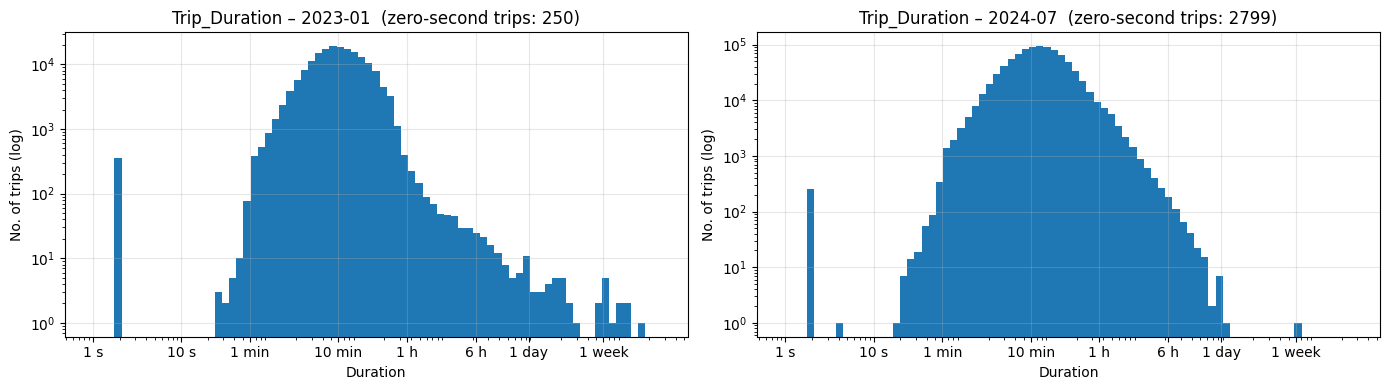

In [65]:
# Histogram with log-spaced bins (1 second to 30 days). Zero-second trips cannot be plotted on a log axis and are counted separately.
bins = np.logspace(0, np.log10(30 * 86400), 80)
ticks = [1, 10, 60, 600, 3600, 6*3600, 86400, 7*86400]
tick_labels = ["1 s", "10 s", "1 min", "10 min", "1 h", "6 h", "1 day", "1 week"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ["2023-01", "2024-07"]):
    d = samples[name]["Trip_Duration"]
    ax.hist(d[d > 0], bins=bins)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(ticks); ax.set_xticklabels(tick_labels)
    ax.set_title(f"Trip_Duration – {name}  (zero-second trips: {(d == 0).sum()})")
    ax.set_xlabel("Duration"); ax.set_ylabel("No. of trips (log)")
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**OBSERVATIONS:**
- There is a tall spike at the far left (trips of 1 to 3 seconds). These are the invalid trips (dock re-locking). After that, there are almost no trips between 3 seconds and about 1 minute. Then the main graph of real rides rising from about 1 minute and peaking around 10 minutes.
- On the right side of the graph, the number of trips curve downward from about 30 minutes to a few hours. Then, we see scattered bars from around 1 day and beyond. This is the upper side of outliers/invalid trips that cannot be real rides. These may be bikes that were not returned (or returned without being docked properly).
- The gap on the left between 3 s and 1 min is where we can put the threshold for a short-trip cutoff.
- On the upper limit (long-trip cutoff), we should check other months or the full Trip Duration dataset.

### 2.3 Candidate cutoffs: how many trips are very short or very long?

To decide the threshold for too-short and too-long trips, we will count how many trips fall below several short cutoffs and above several long cutoffs.

In [66]:
# Count and % of trips shorter than / longer than each candidate cutoff, for the sample months
short_cuts = {"< 3 s": 3, "< 10 s": 10, "< 30 s": 30, "< 1 min": 60, "< 2 min": 120}
long_cuts  = {"> 1 h": 3600, "> 2 h": 7200, "> 3 h": 10800, "> 6 h": 21600, "> 12 h": 43200, "> 1 day": 86400, "> 1 week": 604800}

rows = []
for name, df in samples.items():
    d = df["Trip_Duration"]; n = len(d)
    r = {"month": name, "trips": n}
    for label, cut in short_cuts.items():
        r[label] = f"{(d < cut).sum():,} ({(d < cut).mean()*100:.2f}%)"
    for label, cut in long_cuts.items():
        r[label] = f"{(d > cut).sum():,} ({(d > cut).mean()*100:.3f}%)"
    rows.append(r)
pd.DataFrame(rows).set_index("month").T

month,2023-01,2024-01,2024-07,2025-01,2026-01
trips,180135,204879,906372,202946,137336
< 3 s,601 (0.33%),403 (0.20%),"3,052 (0.34%)",397 (0.20%),"1,169 (0.85%)"
< 10 s,601 (0.33%),403 (0.20%),"3,053 (0.34%)",398 (0.20%),"1,169 (0.85%)"
< 30 s,604 (0.34%),406 (0.20%),"3,077 (0.34%)",401 (0.20%),"1,172 (0.85%)"
< 1 min,666 (0.37%),475 (0.23%),"3,424 (0.38%)",512 (0.25%),"1,213 (0.88%)"
< 2 min,"3,168 (1.76%)","3,304 (1.61%)","12,597 (1.39%)","3,372 (1.66%)","2,636 (1.92%)"
> 1 h,924 (0.513%),"1,921 (0.938%)","24,263 (2.677%)",527 (0.260%),397 (0.289%)
> 2 h,369 (0.205%),385 (0.188%),"5,042 (0.556%)",134 (0.066%),116 (0.084%)
> 3 h,257 (0.143%),255 (0.124%),"1,977 (0.218%)",87 (0.043%),60 (0.044%)
> 6 h,131 (0.073%),165 (0.081%),381 (0.042%),45 (0.022%),42 (0.031%)


**OBSERVATIONS:**
- Short side: the count under 3 s and the count under 1 min are almost the same (ex. 601 vs 666 in Jan 2023). Nearly all trips that are shorter than 1 minute are only a few seconds long. Between 1 and 2 minutes the count jumps to 1.4 to 1.9% of trips which may indicate that these are real short rides (ex. riding for very short distances or a couple of streets).
- Long side: trips over 1 hour are 0.3% of a winter month but 2.7% of July 2024. This is not unusual because riders are more likely to ride long distances for leisure or tourism in warmer months. For over 3 hours the share is 0.04 to 0.22%. Trips that are over 1 day are at most 0.03%.
- The percentage of very short trips is higher in January 2026 (0.85%) than in the other months (0.2 to 0.4%).

### 2.4 Trips that start and end at the same station

A trip that starts and ends at the same station can be real (a round trip) or a dock re-lock (someone took a bike out, found a problem and put it straight back). We can use the trip duration to check this.

In [67]:
# Same-station trips and their durations
for name, df in samples.items():
    same = df[df["Start_Station_Id"] == df["End_Station_Id"]]
    print(f"\n{name}: same-station trips = {len(same):,} ({len(same)/len(df)*100:.1f}% of trips)")
    print("   of which under 1 min:", (same["Trip_Duration"] < 60).sum(),
          " | under 2 min:", (same["Trip_Duration"] < 120).sum(),
          " | median duration:", human(same["Trip_Duration"].median()))


2023-01: same-station trips = 4,620 (2.6% of trips)
   of which under 1 min: 34  | under 2 min: 870  | median duration: 13.4 min

2024-01: same-station trips = 4,464 (2.2% of trips)
   of which under 1 min: 47  | under 2 min: 751  | median duration: 14.5 min

2024-07: same-station trips = 29,213 (3.2% of trips)
   of which under 1 min: 148  | under 2 min: 2876  | median duration: 24.9 min

2025-01: same-station trips = 2,990 (1.5% of trips)
   of which under 1 min: 26  | under 2 min: 732  | median duration: 10.4 min

2026-01: same-station trips = 1,823 (1.3% of trips)
   of which under 1 min: 53  | under 2 min: 465  | median duration: 9.6 min


**OBSERVATION:** 1.3 to 3.2% of trips return to the station they started from, and their median duration is 10 to 25 minutes, so most are actual round trips. A few dozen per month (26 to 148) are under 1 minute; those are already covered by the short-trip cutoff above, so no separate same-station rule is needed.

### 2.5 Time consistency: does End_Time minus Start_Time match Trip_Duration?

In [68]:
# Compare the duration implied by the timestamps with the Trip_Duration column
for name, df in samples.items():
    implied = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()
    diff = (implied - df["Trip_Duration"]).abs()
    print(f"\n{name}:")
    print("   End_Time before Start_Time:     ", (implied < 0).sum())
    print("   |implied - Trip_Duration| > 60 s:", (diff > 60).sum(), f"({(diff > 60).mean()*100:.3f}%)")
    print("   rows where End_Time is missing:  ", df["End_Time"].isna().sum())
    print("   zero-second trips:               ", (df["Trip_Duration"] == 0).sum())


2023-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   0
   zero-second trips:                250

2024-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   4
   zero-second trips:                183

2024-07:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   2170
   zero-second trips:                2799

2025-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   26
   zero-second trips:                166

2026-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   42
   zero-second trips:                347


In [69]:
# The rows with a missing End_Time: what does Trip_Duration look like for them?
df = samples["2024-07"]
no_end_time = df["End_Time"].isna()
print("Rows with missing End_Time:", no_end_time.sum())
print("Their Trip_Duration values:", df.loc[no_end_time, "Trip_Duration"].value_counts().to_dict())
print("Of these, also missing End_Station_Id:", (no_end_time & df["End_Station_Id"].isna()).sum())

Rows with missing End_Time: 2170
Their Trip_Duration values: {0: 2170}
Of these, also missing End_Station_Id: 928


**OBSERVATIONS:**
- The timestamps and `Trip_Duration` agree in every sample month (0 rows differ by more than 60 s) and no trip ends before it starts.
- Every row with a missing `End_Time` has a `Trip_Duration` of **0 seconds**: these are incomplete trip records (the trip never properly ended), not real rides. They will be caught by the short-trip rule, so no separate rule is needed.
- Zero-second trips: 166 to 2,799 per sample month (0.1 to 0.3%).

### 2.6 Station ids and names

In [70]:
# How many distinct stations, and do any station ids have more than one name inside the same month?
for name, df in samples.items():
    n_start = df["Start_Station_Id"].nunique()
    names_per_id = df.groupby("Start_Station_Id")["Start_Station_Name"].nunique()
    print(f"{name}: distinct start stations = {n_start:,}  | ids with more than one name in the month = {(names_per_id > 1).sum()}"
          f"  | rows with a missing Start_Station_Name = {df['Start_Station_Name'].isna().sum():,}")

2023-01: distinct start stations = 651  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 10,630
2024-01: distinct start stations = 773  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2024-07: distinct start stations = 826  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2025-01: distinct start stations = 848  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2026-01: distinct start stations = 918  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0


In [71]:
# Duplicate Trip_Id, and near-duplicates (same bike, same start time, different Trip_Id)
for name, df in samples.items():
    dup_id = df["Trip_Id"].duplicated().sum()
    near = df.duplicated(subset=["Bike_Id", "Start_Time"]).sum()
    print(f"{name}: duplicate Trip_Id = {dup_id}  | same Bike_Id + Start_Time = {near}")

2023-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 0
2024-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 0
2024-07: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 28
2025-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 0
2026-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 9


**OBSERVATIONS:**
- The number of distinct start stations grows from 651 (Jan 2023) to 918 (Jan 2026). This is part of the growth plan of Bike Share Toronto. Station IDs that appear in later years only are the new stations that were added.
- No station id has two different names inside a month. The 10,630 missing `Start_Station_Name` values in Jan 2023 are missing names only. the ids are present, so trips can still be counted per station. We can just use Station IDs and remove Station Names as a feature.
- No duplicate `Trip_Id` in any sample month. A few rows share the same bike and the same start time (28 in Jul 2024).

## 3. Profiling All 39 Months

We will run the same checks over every month to compare the findings from the sample months to the rest of the dataset. The loop reads one file at a time (so it fits in memory), computes a small set of numbers for that month, and throws the month away. The results are saved to `data/profile/` so that they can be reused in EDA.

Note on this section: Created with the help of AI to help profile the full dataset based on the initial findings on the yearly sample files.

### 3.1 Helper functions

In [72]:
def load_raw_month(path):
    """Read one monthly file, standardize the column names and parse the dates. No rows are removed."""
    df = pd.read_csv(path, low_memory=False)
    df = standardize_columns(df)
    df = parse_times(df)
    return df

def profile_month(df, year, month):
    """Compute the checks from Sections 1 and 2 for one month and return them as a dictionary (one row of the profile table)."""
    d = df["Trip_Duration"]
    implied = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()
    month_start = pd.Timestamp(year=year, month=month, day=1)
    month_end = month_start + pd.offsets.MonthBegin(1)

    row = {"year": year, "month": month, "rows": len(df),
           "duplicate_trip_id": int(df["Trip_Id"].duplicated().sum()),
           "same_bike_same_start": int(df.duplicated(subset=["Bike_Id", "Start_Time"]).sum()),
           "start_time_unparsed": int(df["Start_Time"].isna().sum()),
           "start_outside_month": int(((df["Start_Time"] < month_start) | (df["Start_Time"] >= month_end)).sum()),
           "end_before_start": int((implied < 0).sum()),
           "time_mismatch_gt60s": int(((implied - d).abs() > 60).sum()),
           "zero_duration": int((d == 0).sum()),
           "same_station": int((df["Start_Station_Id"] == df["End_Station_Id"]).sum()),
           "same_station_lt60s": int(((df["Start_Station_Id"] == df["End_Station_Id"]) & (d < 60)).sum()),
           "n_start_stations": int(df["Start_Station_Id"].nunique()),
           "n_end_stations": int(df["End_Station_Id"].nunique()),
           "n_bikes": int(df["Bike_Id"].nunique()),
           "casual": int((df["User_Type"].isin(["Casual", "Casual Member"])).sum()),
           "member": int((df["User_Type"].isin(["Member", "Annual Member"])).sum()),
           "ebike": int(df["Bike_Model"].isin(["EFIT", "EFIT G5", "ASTRO"]).sum()),
           }
    for col in STANDARD_COLUMNS:                                  # missing values per column
        row[f"miss_{col}"] = int(df[col].isna().sum())
    for label, cut in short_cuts.items():                          # candidate short cutoffs
        row[f"lt_{cut}s"] = int((d < cut).sum())
    for label, cut in long_cuts.items():                           # candidate long cutoffs
        row[f"gt_{cut}s"] = int((d > cut).sum())
    for p in [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]:
        row[f"dur_p{p*100:g}"] = float(d.quantile(p))
    row["dur_min"] = int(d.min()); row["dur_max"] = int(d.max()); row["dur_mean"] = float(d.mean())
    return row

### 3.2 Run the loop over every monthly file

In [73]:
PROFILE_FILE = f"{PROFILE}/profile_by_month.csv"
STATION_FILE = f"{PROFILE}/station_months.csv"       # one row per station per month: used later for the station first-seen table
HIST_FILE    = f"{PROFILE}/tripdur_hist.npy"        # histogram counts of Trip_Duration: row 0 = training years 2023-2024, row 1 = test years 2025-2026

TRAIN_YEARS = [2023, 2024]        # the project's training years; 2025 is the test year and 2026 Q1 the final check

if os.path.exists(PROFILE_FILE) and os.path.exists(STATION_FILE) and os.path.exists(HIST_FILE):
    profile = pd.read_csv(PROFILE_FILE)
    station_months = pd.read_csv(STATION_FILE)
    hist_train, hist_test = np.load(HIST_FILE)
    print("Loaded the saved profile:", profile.shape)
else:
    profile_rows, station_rows = [], []
    hist_train, hist_test = np.zeros(len(bins) - 1), np.zeros(len(bins) - 1)
    for _, f in file_table.iterrows():
        path = f"{RAW}/{f['year']}/{f['file']}"
        df = load_raw_month(path)
        profile_rows.append(profile_month(df, f["year"], f["month"]))
        # station x month counts (start stations), with the most common name for the id that month
        sm = (df.groupby("Start_Station_Id")
                .agg(trips=("Trip_Id", "size"), name=("Start_Station_Name", lambda s: s.mode().iloc[0] if s.notna().any() else np.nan))
                .reset_index())
        sm["year"], sm["month"] = f["year"], f["month"]
        station_rows.append(sm)
        d = df["Trip_Duration"]
        h = np.histogram(d[d > 0], bins=bins)[0]
        if f["year"] in TRAIN_YEARS:
            hist_train += h
        else:
            hist_test += h
        print(f"{f['year']}-{f['month']:02d}: {len(df):>9,} rows   done")
    profile = pd.DataFrame(profile_rows)
    station_months = pd.concat(station_rows, ignore_index=True)
    profile.to_csv(PROFILE_FILE, index=False)
    station_months.to_csv(STATION_FILE, index=False)
    np.save(HIST_FILE, np.vstack([hist_train, hist_test]))
    print("Saved:", PROFILE_FILE)

profile["year_month"] = profile["year"].astype(str) + "-" + profile["month"].astype(str).str.zfill(2)
profile["split"] = np.where(profile["year"].isin(TRAIN_YEARS), "train 2023-24", "test 2025-26")
TOTAL_ROWS = profile["rows"].sum()
TOTAL_TRAIN = profile.loc[profile["split"] == "train 2023-24", "rows"].sum()
TOTAL_TEST = TOTAL_ROWS - TOTAL_TRAIN
print("Total trips in all 39 files:", f"{TOTAL_ROWS:,}", f"  (training years {TOTAL_TRAIN:,}, test years {TOTAL_TEST:,})")

Loaded the saved profile: (39, 53)
Total trips in all 39 files: 21,030,828   (training years 12,666,235, test years 8,364,593)


### 3.3 Totals by year

In [74]:
# Rows, duplicates and the consistency checks, summed per year
check_cols = ["rows", "duplicate_trip_id", "same_bike_same_start", "start_time_unparsed", "start_outside_month",
              "end_before_start", "time_mismatch_gt60s", "zero_duration", "same_station", "same_station_lt60s"]
by_year = profile.groupby("year")[check_cols].sum()
by_year.loc["TOTAL"] = by_year.sum()
by_year

,rows,duplicate_trip_id,same_bike_same_start,start_time_unparsed,start_outside_month,end_before_start,time_mismatch_gt60s,zero_duration,same_station,same_station_lt60s
year,,,,,,,,,,
2023,5713141,0,20,0,0,49,104,4396,183612,1004
2024,6953094,0,87,0,0,47,112,10873,187477,997
2025,7812520,0,143,0,0,176,266,5479,247238,2185
2026,552073,0,105,0,0,0,32,1535,8376,209
TOTAL,21030828,0,355,0,0,272,514,22283,626703,4395


In [75]:
# Missing values per column as a % of rows, per year
miss_cols = [c for c in profile.columns if c.startswith("miss_")]
miss_pct = profile.groupby("year")[miss_cols].sum().div(profile.groupby("year")["rows"].sum(), axis=0) * 100
miss_pct.columns = [c.replace("miss_", "") for c in miss_pct.columns]
miss_pct.round(3).T

year,2023,2024,2025,2026
Trip_Id,0.000,0.000,0.000,0.000
Trip_Duration,0.000,0.000,0.000,0.000
Start_Station_Id,0.000,0.000,0.000,0.000
Start_Time,0.000,0.000,0.000,0.000
Start_Station_Name,10.416,0.000,0.000,0.000
End_Station_Id,0.052,0.121,0.087,0.269
End_Time,0.000,0.084,0.014,0.090
End_Station_Name,10.477,0.121,0.012,0.269
Bike_Id,0.000,0.000,0.000,0.000
User_Type,0.000,0.000,0.000,0.000


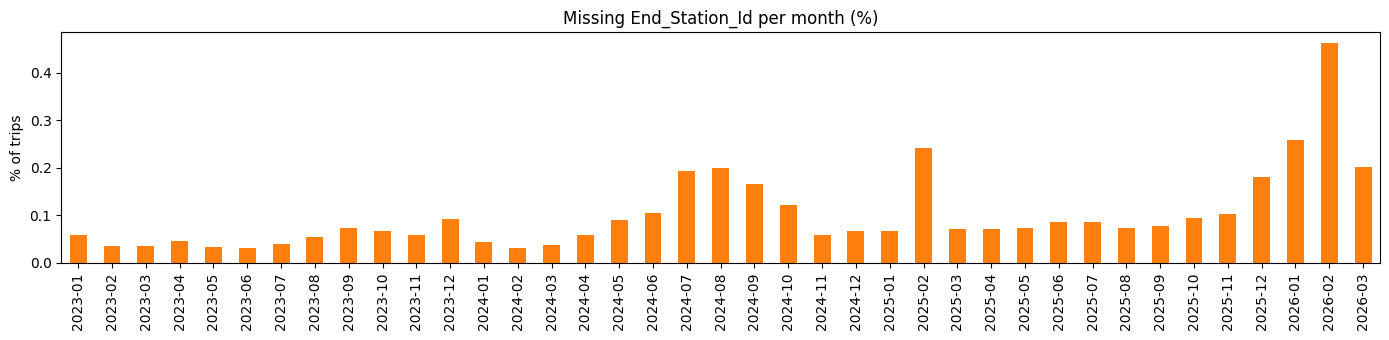

In [76]:
# Missing End_Station_Id per month, as a %
profile["miss_end_pct"] = profile["miss_End_Station_Id"] / profile["rows"] * 100
ax = profile.plot(x="year_month", y="miss_end_pct", kind="bar", figsize=(14, 3.5), legend=False, color="tab:orange")
ax.set_ylabel("% of trips"); ax.set_xlabel(""); ax.set_title("Missing End_Station_Id per month (%)")
plt.tight_layout(); plt.show()

**OBSERVATIONS:**
- The 39 files include **21,030,828 trips**. There is no duplicate `Trip_Id` in any month. Only 355 rows (0.002%) share a bike and a start time.
- `end_before_start` (272 rows) occured in November (2023: 49, 2024: 47, 2025: 176), and `time_mismatch_gt60s` (514 rows) are in March and November. Those may be due to daylight-saving clock changes. The timestamps are off by one hour but `Trip_Duration` shows the actual length of the trips. These are real trips, so we shouldn't just remove them as errors. **Note to the group: Consider the daylight saving clock changes when analyzing the departures and arrivals in these months.**
- There are ver few missing values except for two columns: `Start_Station_Name` is missing in 10.4% of 2023 rows (names only; ids are complete) and `Bike_Model` does not exist in 2023. `End_Station_Id` is missing in 0.05 to 0.27% of rows per year and peaks in the summer of 2024 (bar chart). `End_Time` is missing in 0.01 to 0.09% of rows from 2024, always together with a zero duration (2.5).

- We won't be using `Bike_Model` since it doesn't exist in 2023 and we cannot form an analysis on this given our training dataset.

### 3.4 Volume: trips per month, user type share, stations per month

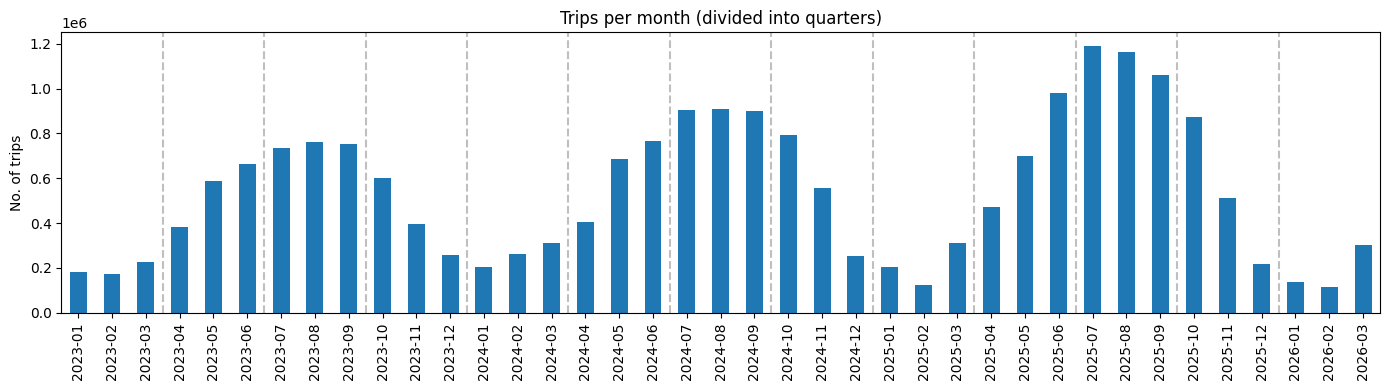

In [77]:
# Trips per month across all years.
ax = profile.plot(x="year_month", y="rows", kind="bar", figsize=(14, 4), legend=False)
for i, ym in enumerate(profile["year_month"]):
    if ym.endswith(("-01", "-04", "-07", "-10")):
        ax.axvline(i - 0.5, color="grey", linestyle="--", alpha=0.5)
ax.set_ylabel("No. of trips"); ax.set_xlabel(""); ax.set_title("Trips per month (divided into quarters)")
plt.tight_layout(); plt.show()

In [78]:
# Trips per year and per quarter
profile["quarter"] = "Q" + ((profile["month"] - 1) // 3 + 1).astype(str)
print("Trips per year:")
print(profile.groupby("year")["rows"].sum().map("{:,}".format))
print("\nTrips per quarter (all years):")
print(profile.groupby("quarter")["rows"].sum().map("{:,}".format))

Trips per year:
year
2023    5,713,141
2024    6,953,094
2025    7,812,520
2026      552,073
Name: rows, dtype: object

Trips per quarter (all years):
quarter
Q1    2,549,589
Q2    5,641,912
Q3    8,384,292
Q4    4,455,035
Name: rows, dtype: object


In [79]:
# Casual vs member share and e-bike share per year
share = profile.groupby("year")[["rows", "casual", "member", "ebike"]].sum()
share["casual_%"] = (share["casual"] / share["rows"] * 100).round(1)
share["ebike_%"]  = (share["ebike"]  / share["rows"] * 100).round(1)
share

,rows,casual,member,ebike,casual_%,ebike_%
year,,,,,,
2023,5713141,5348784,364357,0,93.6,0.0
2024,6953094,1586909,5366185,1073937,22.8,15.4
2025,7812520,2141436,5671084,1513762,27.4,19.4
2026,552073,61170,490903,30234,11.1,5.5


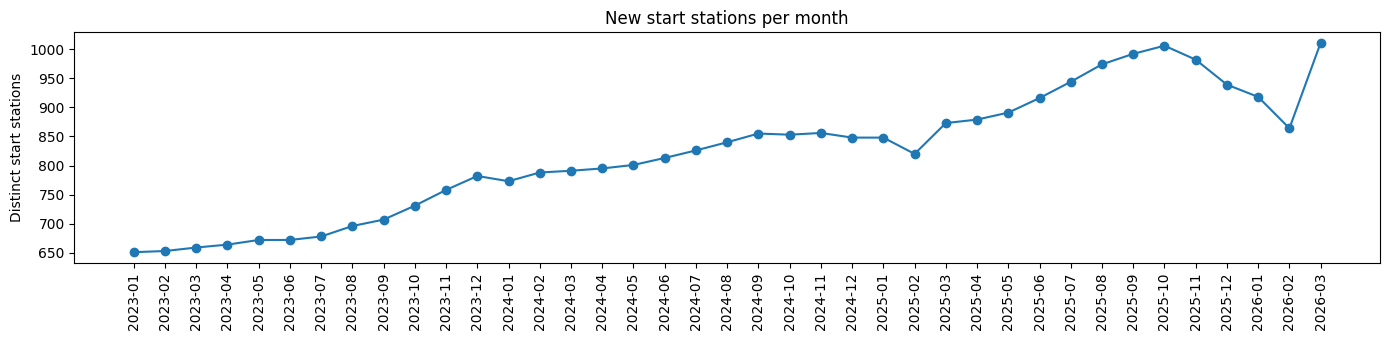

In [80]:
# New start stations per month (station network growth)
ax = profile.plot(x="year_month", y="n_start_stations", kind="line", marker="o", figsize=(14, 3.5), legend=False)
ax.set_ylabel("Distinct start stations"); ax.set_xlabel(""); ax.set_title("New start stations per month")
ax.set_xticks(range(len(profile))); ax.set_xticklabels(profile["year_month"], rotation=90)
plt.tight_layout(); plt.show()

In [81]:
# Recheck the 2023 user type counts
profile[profile["year"] == 2023][["year_month", "rows", "casual", "member"]].assign(
    casual_pct=lambda t: (t["casual"] / t["rows"] * 100).round(1)).set_index("year_month").T

year_month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12
rows,180135.0,172776.0,224545.0,380346.0,589217.0,663691.0,735924.0,760141.0,754303.0,601075.0,393873.0,257115.0
casual,130135.0,130015.0,173584.0,303161.0,506640.0,615182.0,723698.0,760003.0,754303.0,601075.0,393873.0,257115.0
member,50000.0,42761.0,50961.0,77185.0,82577.0,48509.0,12226.0,138.0,0.0,0.0,0.0,0.0
casual_pct,72.2,75.3,77.3,79.7,86.0,92.7,98.3,100.0,100.0,100.0,100.0,100.0


**OBSERVATIONS:**
- Volume: 5.71 M trips in 2023, 6.95 M in 2024. The data also shows that trips continued to grow in 2025 and the first quarter of 2026.
- We can see a pattern of seasonal riders. The rides in Q3 (Jul-Sept) are highest and Q1 (Jan-Mar) are the lowest.
- The 2023 `User_Type` column seems to have incorrect data. For 2023, 93.6% of trips were marked as casual and annual member count in September is 0. But in 2024 onwards, there are only ~23%+ of casual trips. We will not be analyzing user types in our project.
- Stations: the number of active start stations rises steadily from 651 to 1,011. New stations will need to be flagged so that "growth" at a station that just opened is not confused with growing demand.

### 3.5 Trip_Duration: choosing the cutoffs from the training years

Note: (possible data leakage?) The checks so far (schema, types, missing values, duplicates) had to run on every month, because the test data must be loaded and cleaned with the same code as the training data. The *cutoffs* below are a decision, so they are chosen from the training years 2023–2024 only. The test years 2025–2026 are shown next to them only to confirm that the rule still behaves the same there, not to pick the rule.

In [82]:
# Percentiles per year (seconds), using the median of the monthly values as a summary
pcols = ["dur_min", "dur_p0.1", "dur_p1", "dur_p5", "dur_p50", "dur_p95", "dur_p99", "dur_p99.9", "dur_max"]
profile.groupby("year")[pcols].median().map(human)

,dur_min,dur_p0.1,dur_p1,dur_p5,dur_p50,dur_p95,dur_p99,dur_p99.9,dur_max
year,,,,,,,,,
2023,0 s,2 s,1.8 min,3.2 min,11.0 min,38.2 min,1.4 h,6.0 h,28.4 days
2024,0 s,1 s,1.8 min,3.2 min,10.7 min,35.2 min,1.2 h,4.1 h,11.6 days
2025,0 s,2 s,1.8 min,3.2 min,10.7 min,35.3 min,1.3 h,3.5 h,1.0 days
2026,0 s,0 s,1.2 min,3.0 min,9.7 min,27.5 min,42.8 min,2.2 h,1.0 days


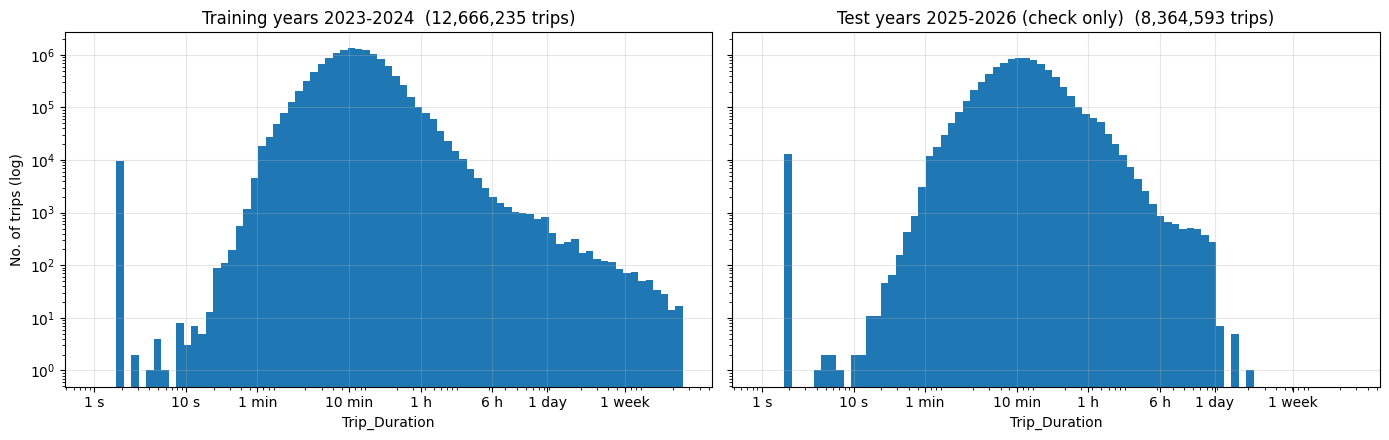

Zero-second trips (not on the log axis): training 15,269  test 7,014


In [83]:
# Histogram of Trip_Duration (log-log): training years on the left, test years on the right for comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, h, title, n in [(axes[0], hist_train, "Training years 2023-2024", TOTAL_TRAIN), (axes[1], hist_test, "Test years 2025-2026 (check only)", TOTAL_TEST)]:
    ax.bar(bins[:-1], h, width=np.diff(bins), align="edge")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(ticks); ax.set_xticklabels(tick_labels)
    ax.set_xlabel("Trip_Duration"); ax.set_title(f"{title}  ({n:,} trips)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("No. of trips (log)")
plt.tight_layout(); plt.show()
print("Zero-second trips (not on the log axis): training", f"{profile.loc[profile['split']=='train 2023-24','zero_duration'].sum():,}",
      " test", f"{profile.loc[profile['split']=='test 2025-26','zero_duration'].sum():,}")

In [84]:
# Candidate cutoffs: count and % of trips, training years (used for the decision) and test years (check only)
tr = profile[profile["split"] == "train 2023-24"]; te = profile[profile["split"] == "test 2025-26"]
cut_table = []
for label, cut in list(short_cuts.items()) + list(long_cuts.items()):
    col = f"lt_{cut}s" if label.startswith("<") else f"gt_{cut}s"
    cut_table.append({"cutoff": label,
                      "trips 2023-24": tr[col].sum(), "% 2023-24": round(tr[col].sum() / TOTAL_TRAIN * 100, 3),
                      "trips 2025-26": te[col].sum(), "% 2025-26": round(te[col].sum() / TOTAL_TEST * 100, 3)})
cut_table = pd.DataFrame(cut_table).set_index("cutoff")
cut_table

,trips 2023-24,% 2023-24,trips 2025-26,% 2025-26
cutoff,,,,
< 3 s,24928,0.197,19880,0.238
< 10 s,24944,0.197,19886,0.238
< 30 s,25194,0.199,20047,0.240
< 1 min,29813,0.235,23396,0.280
< 2 min,164883,1.302,108759,1.300
> 1 h,266657,2.105,214439,2.564
> 2 h,60989,0.482,40732,0.487
> 3 h,28662,0.226,14557,0.174
> 6 h,10885,0.086,3946,0.047


In [85]:
# Check the training years to find the upper limit threshold.
tail = pd.DataFrame({"from": bins[:-1], "to": bins[1:], "trips": hist_train.astype(int)})
tail = tail[tail["from"] >= 3600].copy()
tail["from"] = tail["from"].map(human); tail["to"] = tail["to"].map(human)
tail["change vs previous bin"] = (tail["trips"] / tail["trips"].shift(1)).round(2)
tail.set_index("from").head(22)

,to,trips,change vs previous bin
from,,,
1.0 h,1.3 h,79318,NaN
1.3 h,1.5 h,60889,0.77
1.5 h,1.8 h,35113,0.58
1.8 h,2.2 h,22581,0.64
2.2 h,2.6 h,15004,0.66
2.6 h,3.2 h,10302,0.69
3.2 h,3.8 h,6664,0.65
3.8 h,4.6 h,4523,0.68
4.6 h,5.6 h,3003,0.66


**OBSERVATIONS:**
- The histograms are similar across years, so we can use the same thresholds for all years.
- The training-years histogram has the same shape as the sample months, and the test-years histogram looks the same.

**Short trips cutoff**
- In 2023–2024 (12.7 M trips):
  - Less than 3 seconds: 24,928 trips
  - 3 seconds to 1 minute: 4,885
  - 1-2 minutes: 135,000
- A 1-minute cutoff flags 0.235% of training trips. A 2-minute cutoff would flag 1.3% but would start removing real rides.

**Long trips cutoff**
- On the long-trips side, each bin in the table above shows that there a 60-70% change compared to the previous bit from ~1 hour to 6.7 hours, then plateaus until around 1 day (see the histogram).
- In 2023-2024:
  - more than 3 hours: 28,662 (0.23%)
  - more than 6 hours: 10,885 (0.09%)
  - more than 1 day: 2,599 (0.02%)

- We can choose either 3 hours or 6 hours as our upper threshold/cutoff since the percentage is very small, but to keep more real rides, we will choose the 6 hours.

## 4. Findings and Proposed Cleaning Rules

In [86]:
# The key numbers behind the findings, computed from the profile table.
# Cutoff decisions (R1, R2) use the training years; the test-years value is printed as a check.
n = TOTAL_ROWS
def both(col):
    a, b = tr[col].sum(), te[col].sum()
    return f"{a:,}  ({a/TOTAL_TRAIN*100:.3f}% of 2023-24)   | test years: {b:,} ({b/TOTAL_TEST*100:.3f}%)"
print(f"Total trips                           : {n:,}   (training years {TOTAL_TRAIN:,}, test years {TOTAL_TEST:,})")
print(f"Duplicate Trip_Id                     : {profile['duplicate_trip_id'].sum():,}")
print(f"Trips under 1 min                     : {both('lt_60s')}")
print(f"   of which under 3 s                 : {both('lt_3s')}")
print(f"Trips over 3 h                        : {both('gt_10800s')}")
print(f"Trips over 6 h                        : {both('gt_21600s')}")
print(f"Missing End_Station_Id                : {profile['miss_End_Station_Id'].sum():,}  ({profile['miss_End_Station_Id'].sum()/n*100:.3f}%)")
print(f"Missing End_Time (zero-duration rows) : {profile['miss_End_Time'].sum():,}  ({profile['miss_End_Time'].sum()/n*100:.3f}%)")
print(f"End before start + time mismatch : {profile['end_before_start'].sum():,} + {profile['time_mismatch_gt60s'].sum():,}  ({(profile['end_before_start'].sum()+profile['time_mismatch_gt60s'].sum())/n*100:.4f}%)")
print(f"Missing Start_Station_Name, 2023 only : {profile.loc[profile.year==2023,'miss_Start_Station_Name'].sum():,}  ({profile.loc[profile.year==2023,'miss_Start_Station_Name'].sum()/profile.loc[profile.year==2023,'rows'].sum()*100:.1f}% of 2023 rows)")

Total trips                           : 21,030,828   (training years 12,666,235, test years 8,364,593)
Duplicate Trip_Id                     : 0
Trips under 1 min                     : 29,813  (0.235% of 2023-24)   | test years: 23,396 (0.280%)
   of which under 3 s                 : 24,928  (0.197% of 2023-24)   | test years: 19,880 (0.238%)
Trips over 3 h                        : 28,662  (0.226% of 2023-24)   | test years: 14,557 (0.174%)
Trips over 6 h                        : 10,885  (0.086% of 2023-24)   | test years: 3,946 (0.047%)
Missing End_Station_Id                : 19,612  (0.093%)
Missing End_Time (zero-duration rows) : 7,412  (0.035%)
End before start + time mismatch : 272 + 514  (0.0037%)
Missing Start_Station_Name, 2023 only : 595,075  (10.4% of 2023 rows)


**Findings**
- The 2023 files are written differently from 2024 onwards: column names with spaces (`Trip  Duration` has two), no `Bike_Model`, dates as `mm/dd/yyyy HH:MM` with no seconds, and user labels `Casual Member` / `Annual Member`. We will standardize everything to the 2024 format.
- `End_Station_Id` is read as a float (ex. `7130.0`) because of missing values. This is an ID, so we convert it to an integer.
- The full dataset has 39 files and 21,030,828 trips. Summer months have 4 to 5 times more trips than winter months.
- There are no duplicate `Trip_Id` in any month.
- Missing values:
  - `End_Station_Id`: 19,612 trips (0.05 to 0.27% per year)
  - `End_Time`: 7,412 trips, all with a trip duration of 0 seconds
  - `Start_Station_Name`: 10.4% of 2023 rows, but the IDs are all there
  - `Bike_Model`: does not exist in 2023
- Very short trips (2023-2024):
  - Less than 3 seconds: 24,928 trips
  - 3 seconds to 1 minute: 4,885
  - 1 to 2 minutes: 135,000
- Very long trips (2023-2024): the histogram goes down steadily until ~6.7 hours and then flattens out until 1 day and beyond (max is 28 days).
  - More than 3 hours: 28,662 (0.23%)
  - More than 6 hours: 10,885 (0.09%)
  - More than 1 day: 2,599 (0.02%)
- 272 trips end before they start and 514 have timestamps that don't match `Trip_Duration`. All of these are in March and November (daylight saving). These are real trips.
- The 2023 `User_Type` values don't match 2024 onwards (93.6% casual in 2023 vs ~23% in 2024). We will not analyze user types.
- The number of stations grows from 651 (Jan 2023) to 1,011 (Mar 2026).

**Cleaning rules**

We will flag the rows instead of deleting them, so we can still count them in the EDA and decide separately what to include for departures and arrivals.

- **R1 - Short trips:** Almost all trips under 1 minute are only a few seconds long (dock re-locks), and real rides start after 1 minute. We flag `Trip_Duration < 60 s` as `flag_short`. This affects 29,813 trips in 2023-2024 (0.235%). This also covers the rows with a missing `End_Time` since they all have a 0 second duration.
- **R2 - Long trips:** The ride curve flattens into unreturned-bike noise after ~6 hours. We flag `Trip_Duration > 6 h` as `flag_long`. This affects 10,885 trips in 2023-2024 (0.09%). We chose 6 hours instead of 3 hours to keep more real rides.
- **R3 - Missing end station:** 0.09% of trips have no `End_Station_Id` but the departure still happened. We flag these as `flag_no_end`. We keep them when counting departures and exclude them when counting arrivals. This affects 19,612 trips.
- **R4 - Duplicates:** No duplicates were found, but the loading code still drops exact duplicate `Trip_Id` as a safety check. 0 rows affected.
- `is_valid` is True when none of the three flags is set.

Not flagged:
- Same-station trips are mostly real round trips (median 10 to 25 minutes), so we keep them.
- The daylight saving timestamp issues are real trips, so we keep them. **Note to the group: Consider the daylight saving clock changes when counting departures and arrivals in March and November.**

**Column decisions**
- Convert all months to the 2024 column names, parse the dates using the format for each year, and convert station IDs to `Int64`.
- Remove `Start_Station_Name` and `End_Station_Name` as features. We can just use the station IDs.
- We will not use `User_Type` or `Bike_Model` in the analysis.
- Flag new stations based on the month they first appear, so growth at a new station is not confused with growing demand.

**Note on data leakage:** The checks for schema, types, missing values and duplicates were run on all 39 months because the test data has to be cleaned with the same code. The cutoffs for R1 and R2 were chosen from the training years (2023-2024) only. The test years (2025-2026) were only used to check that the rules behave the same.

**Next step**
- Create notebook 01_load_cleaning that applies the rules to all 39 months and saves one clean file per month plus a table of counts.


## Notebook 01: Cleaning the dataset and Defining the target variable
This is a continuation of Notebook 00  
Target variable: HOURLY DEPARTURES (trip counts) PER STATION.

### 5. APPLYING THE CLEANING RULES
Every rule below is justified with numbers from Sections 1-3. The thresholds were chosen from the TRAINING years (2023-24) only; the test years are used to check that the rule behaves the same way, not to pick it.

In R1 we standardize column names and parse dates (already done inside load_raw_month).
Why: 2023 uses spaces + month/day/year, 2024+ uses underscores + ISO dates.
Without this the 39 files cannot be stacked.

In R2 we drop trips shorter than 60 seconds.
Why: the histogram has a spike at 1-3 s (dock re-locks / failed undocks) and an almost empty gap from 3 s to approx. 1 min. 24,928 of the 29,813 trips under 1 min (0.235% of training trips) are under 3 s. The 1-2 min bin ( approx. 135,000 trips) is a normal rise in real short rides, so the cutoff stays at 1 min, not 2.
All rows with a missing End_Time have Trip_Duration = 0, so R2 removes them too.

In R3 we drop trips longer than 6 hours (21,600 s).
Why: the tail drops about 30-40% per bin up to ~6 h (a smooth decay of real rides), then flattens into scattered values up to weeks (bikes not returned or not docked properly). Over 6 h is only 0.086% of training trips, and 6 h keeps more real rides than the stricter 3 h option.

In R4 we keep rows with a missing End_Station_Id (0.05-0.27% per year).
Why: the target counts DEPARTURES, which only need Start_Station_Id and
Start_Time. Both are never missing. Dropping these rows would remove real departures and bias the counts down. End_Station_Id is converted to Int64.

In R5 we keep the daylight-saving rows (end_before_start, time mismatch > 60 s).
Why: they are real trips (Trip_Duration is correct, only the clock is off by 1 h). The target only uses Start_Time, so these rows are fine. The DST problem is handled in the hourly grid instead (Section 6): the non-existent spring hour is removed and the repeated autumn hour is flagged.

In R6 we keep rows that share a Bike_Id and Start_Time (355 rows, 0.002%).
Why: Trip_Id is unique, we cannot tell which row is "wrong", and the effect on hourly counts is negligible (355 trips out of 21 million).

In R7 we drop columns that will not be used: Bike_Model (not in 2023), User_Type (2023 labels are wrong), Start/End_Station_Name (10% missing in 2023, ids are enough), Bike_Id, Trip_Duration (only needed for R2/R3), End_Time.

In R8 we zero-fill the hourly counts only for ACTIVE station-months.
Why: an hour with no departures at a working station is a real 0 and the model must see it. But a station that has not opened yet (network grew from 651 to ~1,000 stations) or is closed for the winter would get thousands of fake zeros. A station is "active" in a month if it has at least one trip in that month (station_months table from Section 3.2).

R9  DROP rows with a missing Start_Station_Id or Start_Time (counted in the log).
Why: a departure that cannot be placed at a station and an hour cannot be part of the target. Expected to be a handful of rows at most.

In [87]:
import io, time
import requests

MIN_DURATION_S = 60          # R2
MAX_DURATION_S = 6 * 3600    # R3
TEST_YEARS = [2025]          # 2026 Q1 = final check
PROCESSED = f"{DATA}/processed"
os.makedirs(PROCESSED, exist_ok=True)


# the hourly station-hour table is kept IN MEMORY ONLY. Only small summary files are saved (cleaning log, summary
# workbook) and, in the separate demand-columns section, the trip files with the new columns.
EXCEL_ROW_LIMIT = 1_048_575      # data rows per Excel sheet (used when writing Excel files)


def clean_trips(df):
    # Apply R2, R3, R4, R7 to one standardized month. Returns (clean trips, log dict).
    d = df["Trip_Duration"]
    too_short = d < MIN_DURATION_S                                   # R2
    too_long = d > MAX_DURATION_S                                    # R3
    log = {"raw_rows": len(df),
           "drop_short": int(too_short.sum()),
           "drop_long": int(too_long.sum()),
           # sanity check: every missing End_Time should already be removed by R2
           "missing_end_time_kept": int((df["End_Time"].isna() & ~too_short & ~too_long).sum())}
    df = df[~(too_short | too_long)]
    # rows with no start station or no start time cannot be assigned to a
    # station-hour, so they are dropped (R9) and now COUNTED, so the row accounting adds up.
    # (Section 3 shows these as 0.000% because that table is rounded to 3 decimals.)
    before_key = len(df)
    df = df.dropna(subset=["Start_Station_Id", "Start_Time"])
    log["drop_missing_key"] = before_key - len(df)
    log["kept_missing_end_station"] = int(df["End_Station_Id"].isna().sum())   # R4: kept
    df = df.assign(End_Station_Id=df["End_Station_Id"].astype("Int64"))
    log["clean_rows"] = len(df)
    return df[["Start_Station_Id", "Start_Time", "End_Station_Id"]], log   # R7

### 5.1 Cleaning Summary

In [88]:
by_year = cleaning_log.groupby("year")[
    ["raw_rows", "drop_short", "drop_long", "drop_missing_key", "clean_rows",
     "kept_missing_end_station", "missing_end_time_kept",
     "trips_in_removed_dst_hour"]
].sum()
by_year.loc["TOTAL"] = by_year.sum()
by_year["% removed"] = (
    (by_year["drop_short"] + by_year["drop_long"] + by_year["drop_missing_key"])
    / by_year["raw_rows"] * 100
).round(3)

print(by_year)
assert cleaning_log["missing_end_time_kept"].sum() == 0
assert cleaning_log["trips_in_removed_dst_hour"].sum() < 100

       raw_rows  drop_short  drop_long  drop_missing_key  clean_rows  kept_missing_end_station  missing_end_time_kept  trips_in_removed_dst_hour  % removed
year                                                                                                                                                       
2023    5713141       12031       6896                 0     5694214                      1684                      0                          0      0.331
2024    6953094       17782       3989                 0     6931323                      3317                      0                          0      0.313
2025    7812520       19913       3799                 1     7788807                      3647                      0                          0      0.304
2026     552073        3483        147                 0      548443                       353                      0                          0      0.658
TOTAL  21030828       53209      14831                 1    2096

```markdown
### 5.2 Methodological Justification for Station Demand Classification

To construct a robust spatial profile of our station network, we categorize stations into discrete demand classes (**High**, **Medium**, and **Low**). Rather than applying arbitrary thresholds, this classification is derived mathematically to represent the systemic scale of each station.

#### 1. Calculation and Percentile Cutoffs
- **Base Metric (Daily Demand Rate):** For each station, we compute the average daily trip rate as:
  $$\text{Demand Rate} = \frac{\text{Total Valid Trips}}{\text{Active Operating Days}}$$
  By using *active operating days* (days where the station recorded at least one trip) rather than calendar days, we prevent new stations (which opened mid-year) or seasonally closed stations from being artificially classified as "Low" demand due to inactive periods.
- **Data Splitting & Calibration:** To prevent data leakage, the baseline demand rates and percentile cutoffs are calibrated **exclusively** on the training period (2023–2024).
- **Percentile Thresholds:** Cutoffs are determined using the 33.3rd and 66.7th percentiles of the training distribution, splitting active stations into three equally sized tiers:
  - **Low Demand:** Stations in the bottom 33.3% tier (e.g., peripheral or highly residential stations).
  - **Medium Demand:** Stations in the middle 33.3% tier.
  - **High Demand:** Stations in the top 33.3% tier (e.g., major transit hubs, core business districts, or dense waterfront corridors).
- **Cold-Start Handling:** Stations first appearing in the test years (2025–2026) are assigned demand rates based on their first 3 active months of operating data to prevent cold-start classification bias.
```

```markdown
#### 2. Why Demand Classes Must Be Stable Daily Rates (Not Hourly-Varying)

An intuitive question is whether these demand classes should vary dynamically by hour (e.g., classifying a station as "High" during morning rush hour and "Low" at midnight). Methodologically, we strictly enforce **stable daily/structural rates** for three critical reasons:

1. **Prevention of Target Leakage:** Our machine learning target variable is *hourly departures* per station. If our station demand classification were computed on an hourly basis, the feature would become a direct mathematical proxy of the target variable itself. This would introduce catastrophic data leakage, inflating training performance while making the model useless for true forecasting.
2. **Representation of Physical Archetype & Capacity:** The structural tier of a station (e.g., a 40-dock flagship station at Union Station vs. a 12-dock residential station in the suburbs) is a static physical attribute. A high-capacity station remains a structural "High Demand" asset even at 3:00 AM when it records zero trips. Keeping this rate stable allows the model to map the physical footprint and tier of the station.
3. **Preservation of Temporal Feature Interactions:** Diurnal fluctuations (rush hours, night-time drops) and calendar variations (weekends vs. weekdays) are already explicitly modeled by our cyclic features (`hour_sin`, `hour_cos`, `month_sin`, `month_cos`) and calendar flags. By keeping the station tier static, the machine learning models can learn the complex interactions between these temporal patterns and the station's capacity—for instance, how a commute pattern peaks intensely at a "High" demand station but is virtually absent at a "Low" demand station.
```

### 5.2 Defining target variable. Station demand lables: Low/Medium/High
* Demand rate = valid trips / active days, using training years only.
* Stations first seen after training use their first 3 active months.
* Cutoffs are the 33.3rd and 66.7th percentiles of station demand rates.
In this section demand columns are also added to trip files
Output: data/processed/bikeshare_YYYY_MM_demand.csv
Contains every original trip plus Start_Station_Demand and End_Station_Demand.

In [89]:
DEMAND_LABELS = ["Low", "Medium", "High"]
LAUNCH_MONTHS = 3
STATION_MONTH_FILE = f"{PROCESSED}/station_month_stats.csv"
HOURLY_DEMAND_FILE = f"{PROCESSED}/hourly_demand_per_station.csv"

def station_month_stats(df, year, month):
    """Valid trips and active days per station, for starts and ends."""
    valid = df[df["Trip_Duration"].between(MIN_DURATION_S, MAX_DURATION_S)]
    out = {}

    for side, id_col, time_col in [
        ("start", "Start_Station_Id", "Start_Time"),
        ("end", "End_Station_Id", "End_Time"),
    ]:
        v = valid[[id_col, time_col]].dropna()
        v = pd.DataFrame({
            "station_id": v[id_col].astype("int64"),
            "day": v[time_col].dt.normalize(),
        })
        out[f"{side}_trips"] = v.groupby("station_id").size()
        out[f"{side}_days"] = v.drop_duplicates().groupby("station_id").size()

    out = pd.DataFrame(out).fillna(0).astype("int64")
    out.index.name = "station_id"
    out = out.reset_index()
    out["year"], out["month"] = year, month
    return out

if os.path.exists(STATION_MONTH_FILE):
    sm = pd.read_csv(STATION_MONTH_FILE)
else:
    sm = pd.concat([
        station_month_stats(
            load_raw_month(f"{RAW}/{int(f.year)}/{f.file}"),
            int(f.year), int(f.month)
        )
        for f in file_table.itertuples()
    ], ignore_index=True)
    sm.to_csv(STATION_MONTH_FILE, index=False)

ids = pd.Index(sorted(sm["station_id"].unique()), name="station_id")
station_classes = pd.DataFrame(index=ids)

for side in ["start", "end"]:
    trips_col, days_col = f"{side}_trips", f"{side}_days"

    train = sm[sm["year"].isin(TRAIN_YEARS)].groupby("station_id")[
        [trips_col, days_col]
    ].sum()
    train = train[train[days_col] > 0]
    train_rate = train[trips_col] / train[days_col]

    later = sm[~sm["station_id"].isin(train_rate.index) & (sm[days_col] > 0)]
    launch = (
        later.sort_values(["station_id", "year", "month"])
        .groupby("station_id")
        .head(LAUNCH_MONTHS)
        .groupby("station_id")[[trips_col, days_col]]
        .sum()
    )
    launch_rate = launch[trips_col] / launch[days_col]

    c1, c2 = np.quantile(train_rate, [1 / 3, 2 / 3])
    rate = pd.concat([train_rate, launch_rate]).reindex(ids).fillna(0)

    station_classes[f"{side}_rate"] = rate
    station_classes[f"{side}_demand"] = pd.cut(
        rate, [-np.inf, c1, c2, np.inf], labels=DEMAND_LABELS
    ).astype(str)

    print(f"{side.title()} cutoffs: Low <= {c1:.2f} < "
          f"Medium <= {c2:.2f} < High")
    print(station_classes[f"{side}_demand"]
          .value_counts().reindex(DEMAND_LABELS).to_dict())


Start cutoffs: Low <= 6.27 < Medium <= 26.61 < High
{'Low': 464, 'Medium': 326, 'High': 321}
End cutoffs: Low <= 5.74 < Medium <= 25.36 < High
{'Low': 464, 'Medium': 325, 'High': 322}


### 6. Building the target: Hourly departures per station
One row per (station, hour). trips = number of cleaned trips that started at that station in that clock hour. Built month by (each raw file is read, aggregated and released) so it fits in Colab memory, The table lives in memory only: nothing hourly is written to disk, so every run of this cell re-reads the raw files.
Daylight saving (R5): timestamps are local clock time.
- Spring forward (March): the 02:00-03:00 hour does not exist. If it stayed in the grid it would be a fake zero for every station, so that hour is REMOVED.
- Fall back (November): the 01:00-02:00 hour happens twice but the clock cannot tell the two apart, so its count mixes two real hours (about double demand). It is KEPT but flagged (dst_fallback_hour = True) so a model or the group can exclude it or treat it separately.

The cell below also counts how many trips start inside the removed hour; that should be ~0 if the files really store local clock time.

In [90]:

def dst_flags(hours):
    s = pd.Series(hours)

    nonexistent = s.dt.tz_localize(
        "America/Toronto",
        ambiguous=np.ones(len(s), dtype=bool),
        nonexistent="NaT",
    ).isna()

    ambiguous = s.dt.tz_localize(
        "America/Toronto",
        ambiguous="NaT",
        nonexistent="shift_forward",
    ).isna()

    return nonexistent.to_numpy(), ambiguous.to_numpy()

def build_month_hourly(clean, year, month, active_stations):
    start = pd.Timestamp(year=year, month=month, day=1)
    end = start + pd.offsets.MonthBegin(1)

    hours = pd.date_range(start, end, freq="h", inclusive="left")
    nonexistent, ambiguous = dst_flags(hours)
    fallback_hours = hours[ambiguous & ~nonexistent]
    hours = hours[~nonexistent]

    tmp = pd.DataFrame({
        "station_id": clean["Start_Station_Id"].astype("int64"),
        "hour": clean["Start_Time"].dt.floor("h"),
    })
    counts = tmp.groupby(["station_id", "hour"]).size()

    grid = pd.MultiIndex.from_product(
        [np.sort(active_stations.astype("int64")), hours],
        names=["station_id", "hour"],
    )
    out = counts.reindex(grid, fill_value=0)
    lost = int(counts.sum() - out.sum())

    out = out.rename("trips").reset_index()
    out["station_id"] = out["station_id"].astype("int16")
    out["trips"] = out["trips"].astype("int16")
    out["dst_fallback_hour"] = out["hour"].isin(fallback_hours)
    return out, lost

log_rows, parts = [], []

for f in file_table.itertuples():
    y, m = int(f.year), int(f.month)
    raw = load_raw_month(f"{RAW}/{y}/{f.file}")
    clean, log = clean_trips(raw)

    active = station_months.loc[
        (station_months["year"] == y) & (station_months["month"] == m),
        "Start_Station_Id",
    ].dropna().astype("int64").unique()

    hourly_m, lost = build_month_hourly(clean, y, m, active)

    log.update({
        "year": y,
        "month": m,
        "trips_in_removed_dst_hour": lost,
        "station_hours": len(hourly_m),
        "trips_in_target": int(hourly_m["trips"].sum()),
    })

    log_rows.append(log)
    parts.append(hourly_m)

    print(f"{y}-{m:02d}: {log['raw_rows']:,} raw -> "
          f"{log['clean_rows']:,} clean | {len(hourly_m):,} station-hours")
    del raw, clean

cleaning_log = pd.DataFrame(log_rows)

cleaning_log["unexplained"] = (
    cleaning_log["raw_rows"]
    - cleaning_log["drop_short"]
    - cleaning_log["drop_long"]
    - cleaning_log["drop_missing_key"]
    - cleaning_log["clean_rows"]
)

assert cleaning_log["raw_rows"].sum() == TOTAL_ROWS
assert cleaning_log["unexplained"].eq(0).all()


2023-01: 180,135 raw -> 179,338 clean | 484,344 station-hours
2023-02: 172,776 raw -> 172,259 clean | 438,816 station-hours
2023-03: 224,545 raw -> 223,897 clean | 489,637 station-hours
2023-04: 380,346 raw -> 379,229 clean | 478,080 station-hours
2023-05: 589,217 raw -> 587,581 clean | 499,968 station-hours
2023-06: 663,691 raw -> 661,666 clean | 483,840 station-hours
2023-07: 735,924 raw -> 733,606 clean | 504,432 station-hours
2023-08: 760,141 raw -> 757,479 clean | 517,824 station-hours
2023-09: 754,303 raw -> 751,556 clean | 509,040 station-hours
2023-10: 601,075 raw -> 598,812 clean | 543,864 station-hours
2023-11: 393,873 raw -> 392,799 clean | 545,760 station-hours
2023-12: 257,115 raw -> 255,992 clean | 581,808 station-hours
2024-01: 204,879 raw -> 204,239 clean | 575,112 station-hours
2024-02: 261,774 raw -> 261,040 clean | 548,448 station-hours
2024-03: 312,613 raw -> 311,656 clean | 587,713 station-hours
2024-04: 403,788 raw -> 402,360 clean | 572,400 station-hours
2024-05:

### 6.1 Add calendar and demand labels and save one hourly CSV per month


In [91]:
if "parts" in globals():
    hourly = pd.concat(parts, ignore_index=True)
    del parts

# Lookup indexed by station and hour.
lookup = hourly[["station_id", "hour"]].drop_duplicates()
lookup = lookup.join(
    station_classes[["start_demand", "end_demand"]],
    on="station_id",
).set_index(["station_id", "hour"])

def match_demand(df, side):
    """Match the trip's station and timestamp to a station-hour label."""
    prefix = side.title()
    keys = pd.MultiIndex.from_arrays([
        df[f"{prefix}_Station_Id"],
        df[f"{prefix}_Time"].dt.floor("h"),
    ])
    return lookup[f"{side}_demand"].reindex(keys).to_numpy()

for f in file_table.itertuples():
    y, m = int(f.year), int(f.month)
    df = load_raw_month(f"{RAW}/{y}/{f.file}")

    df["start_demand"] = match_demand(df, "start")
    df["end_demand"] = match_demand(df, "end")

    path = f"{PROCESSED}/bikeshare_{y}_{m:02d}_demand.csv"
    df.to_csv(path, index=False)
    print(f"{y}-{m:02d}: saved {len(df):,} trips with demand labels")

# Keep calendar features in memory for subsequent EDA—not in the trip CSVs.
hourly = add_calendar_features(hourly)
train = hourly[hourly["split"] == "train"]
y_train = train["trips"]

2023-01: saved 180,135 trips with demand labels
2023-02: saved 172,776 trips with demand labels
2023-03: saved 224,545 trips with demand labels
2023-04: saved 380,346 trips with demand labels
2023-05: saved 589,217 trips with demand labels
2023-06: saved 663,691 trips with demand labels
2023-07: saved 735,924 trips with demand labels
2023-08: saved 760,141 trips with demand labels
2023-09: saved 754,303 trips with demand labels
2023-10: saved 601,075 trips with demand labels
2023-11: saved 393,873 trips with demand labels
2023-12: saved 257,115 trips with demand labels
2024-01: saved 204,879 trips with demand labels
2024-02: saved 261,774 trips with demand labels
2024-03: saved 312,613 trips with demand labels
2024-04: saved 403,788 trips with demand labels
2024-05: saved 686,392 trips with demand labels
2024-06: saved 766,868 trips with demand labels
2024-07: saved 906,372 trips with demand labels
2024-08: saved 907,154 trips with demand labels
2024-09: saved 901,638 trips with demand

### 7. TARGET VARIABLE EXPLORATION (trips per station per hour)
### 7.1 Range, spread, skewness, zeros, overdispersion

In [96]:
target_stats = pd.Series({
    "rows": len(y_train),
    "mean": y_train.mean(),
    "std": y_train.std(),
    "variance": y_train.var(),
    "variance / mean": y_train.var() / y_train.mean(),
    "min": y_train.min(),
    "median": y_train.median(),
    "p95": y_train.quantile(0.95),
    "p99": y_train.quantile(0.99),
    "p99.9": y_train.quantile(0.999),
    "max": y_train.max(),
    "skewness": y_train.skew(),
    "share of zeros (%)": (y_train == 0).mean() * 100,
})
print(target_stats.round(3))

# Variance/mean inside comparable hours (same month, weekday/weekend, hour of day). Still
# inflated by differences between stations, but a value well above 1 means the counts are
# more spread out than a Poisson model assumes (overdispersion).
cond = train.groupby(["month", "is_weekend", "hour_of_day"])["trips"].agg(["mean", "var"])
print("Median variance/mean within month x weekend x hour:", round((cond["var"] / cond["mean"]).median(), 2))

rows                  1.327936e+07
mean                  9.510000e-01
std                   2.113000e+00
variance              4.467000e+00
variance / mean       4.698000e+00
min                   0.000000e+00
median                0.000000e+00
p95                   5.000000e+00
p99                   1.000000e+01
p99.9                 1.900000e+01
max                   1.740000e+02
skewness              5.180000e+00
share of zeros (%)    6.554300e+01
dtype: float64
Median variance/mean within month x weekend x hour: 2.39


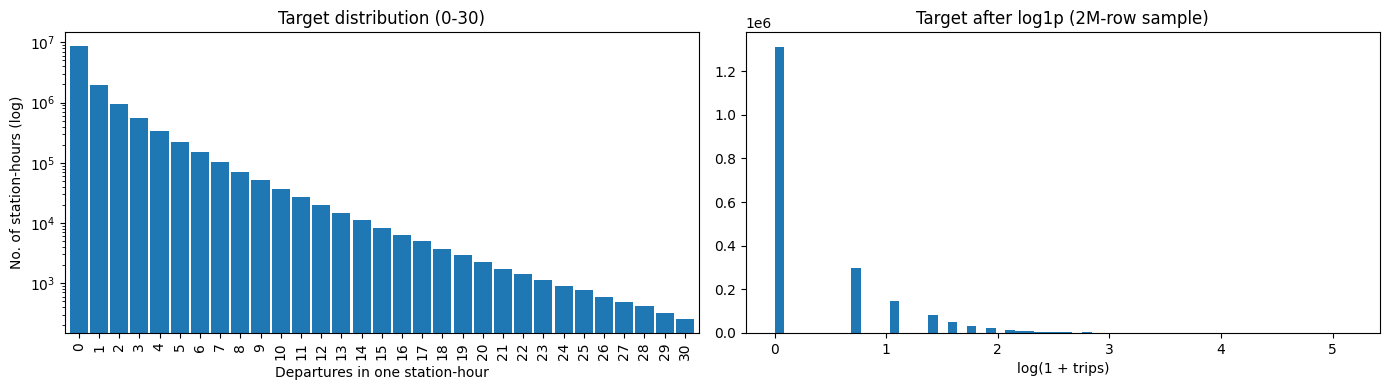

In [97]:
# 7.2 Distribution of the target
# ------------------------------------------------------------------------------
vc = y_train.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vc.head(31).plot(kind="bar", ax=axes[0], width=0.9)
axes[0].set_yscale("log"); axes[0].set_xlabel("Departures in one station-hour")
axes[0].set_ylabel("No. of station-hours (log)"); axes[0].set_title("Target distribution (0-30)")
axes[1].hist(np.log1p(y_train.sample(min(len(y_train), 2_000_000), random_state=0)), bins=60)
axes[1].set_xlabel("log(1 + trips)"); axes[1].set_title("Target after log1p (2M-row sample)")
plt.tight_layout(); plt.show()

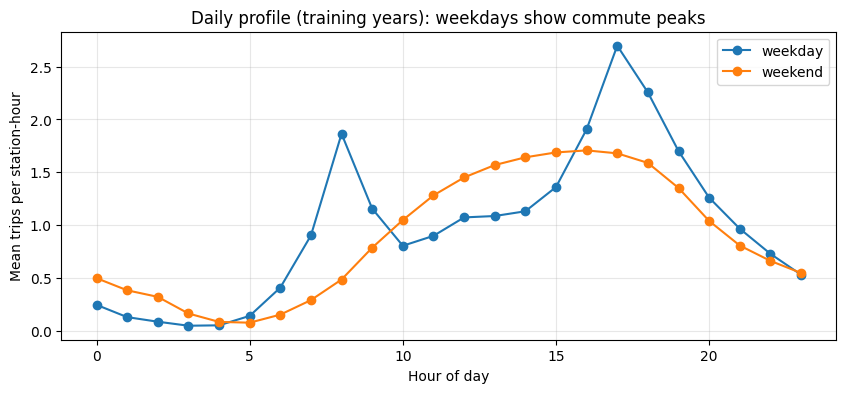

In [98]:
# 7.3 Time patterns: hour of day, weekday/weekend, season, network growth
# ------------------------------------------------------------------------------
prof = train.groupby(["is_weekend", "hour_of_day"])["trips"].mean().unstack(0)
prof.columns = ["weekday", "weekend"]
ax = prof.plot(figsize=(10, 4), marker="o")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean trips per station-hour")
ax.set_title("Daily profile (training years): weekdays show commute peaks")
ax.grid(alpha=0.3); plt.show()


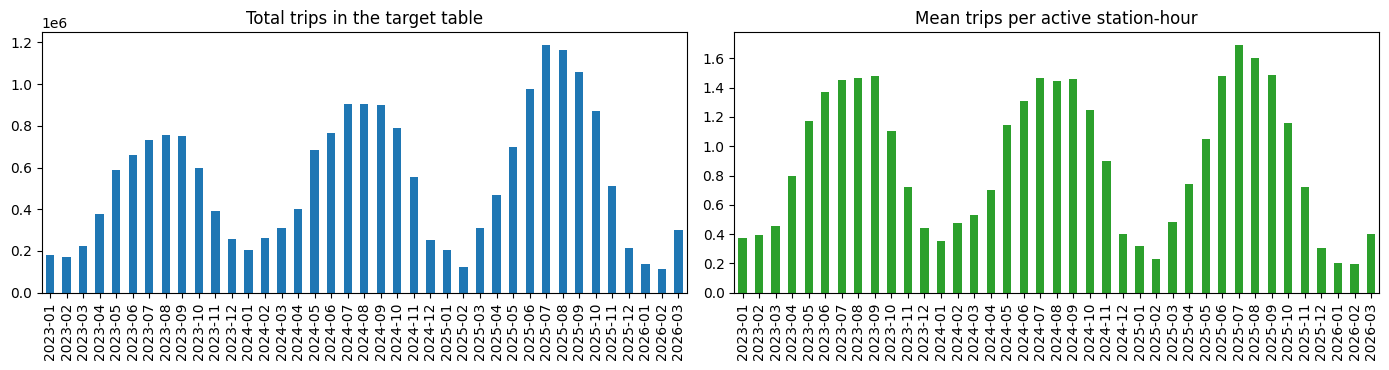

In [99]:
# Mean trips per ACTIVE station-hour per month. Dividing by the number of active stations
# separates "more demand per station" from "more stations".
monthly = hourly.groupby(["year", "month"])["trips"].agg(total="sum", per_station_hour="mean")
monthly.index = [f"{a}-{b:02d}" for a, b in monthly.index]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
monthly["total"].plot(kind="bar", ax=axes[0]); axes[0].set_title("Total trips in the target table")
monthly["per_station_hour"].plot(kind="bar", ax=axes[1], color="tab:green")
axes[1].set_title("Mean trips per active station-hour")
plt.tight_layout(); plt.show()

count    903.000
mean       0.876
std        0.924
min        0.000
25%        0.140
50%        0.522
75%        1.359
max        5.475
Name: mean_trips_per_hour, dtype: float64

IQR rule: 25 of 903 stations have a mean above 3.19 trips/hour
Top 10 busiest stations:
             mean_trips_per_hour  zero_share  active_hours
station_id                                               
7006                      5.475       0.206         17542
7076                      5.288       0.253         17542
7033                      4.784       0.213         17542
7030                      4.577       0.217         17542
7542                      4.082       0.232         17542
7016                      4.004       0.356         17542
7078                      3.964       0.249         17542
7418                      3.907       0.205         17542
7038                      3.898       0.294         17542
7720                      3.847       0.214         17542


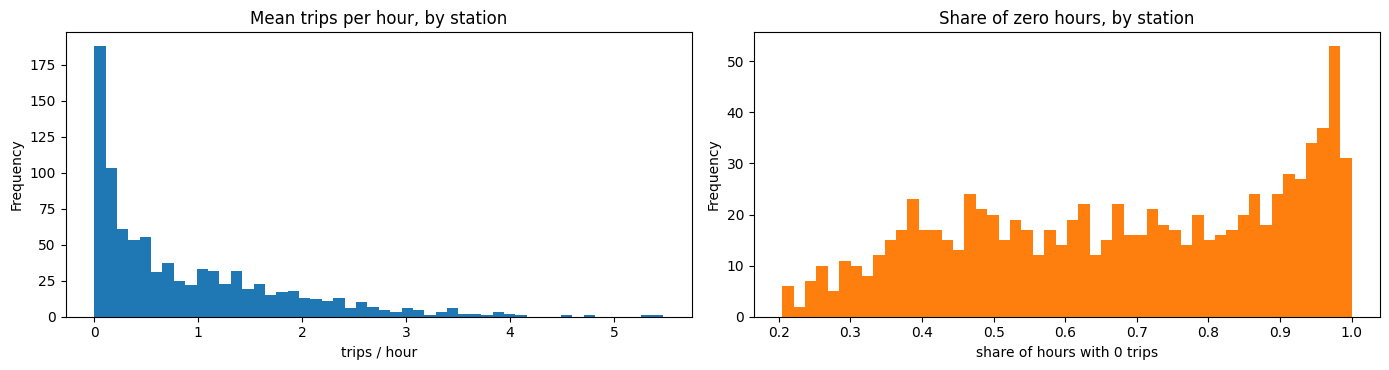

In [100]:
# 7.4 Differences between stations and station-level outliers
# ------------------------------------------------------------------------------
station_stats = pd.DataFrame({
    "mean_trips_per_hour": train.groupby("station_id")["trips"].mean(),
    "zero_share": (y_train == 0).groupby(train["station_id"]).mean(),
    "active_hours": train.groupby("station_id").size(),
})
print(station_stats["mean_trips_per_hour"].describe().round(3))

q1, q3 = station_stats["mean_trips_per_hour"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
busy = station_stats[station_stats["mean_trips_per_hour"] > upper_fence]
print(f"\nIQR rule: {len(busy)} of {len(station_stats)} stations have a mean above {upper_fence:.2f} trips/hour")
print("Top 10 busiest stations:\n", station_stats.sort_values("mean_trips_per_hour", ascending=False).head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
station_stats["mean_trips_per_hour"].plot(kind="hist", bins=50, ax=axes[0])
axes[0].set_title("Mean trips per hour, by station"); axes[0].set_xlabel("trips / hour")
station_stats["zero_share"].plot(kind="hist", bins=50, ax=axes[1], color="tab:orange")
axes[1].set_title("Share of zero hours, by station"); axes[1].set_xlabel("share of hours with 0 trips")
plt.tight_layout(); plt.show()

rows                  1.327936e+07
mean                  9.510000e-01
std                   2.113000e+00
variance              4.467000e+00
variance / mean       4.698000e+00
min                   0.000000e+00
median                0.000000e+00
p95                   5.000000e+00
p99                   1.000000e+01
p99.9                 1.900000e+01
max                   1.740000e+02
skewness              5.180000e+00
share of zeros (%)    6.554300e+01
dtype: float64
Median variance/mean within month x weekend x hour: 2.39


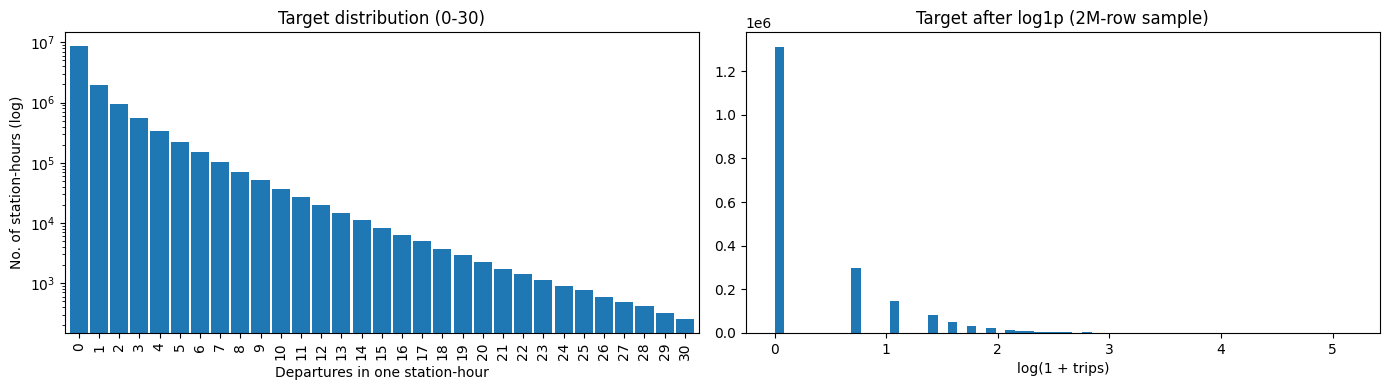

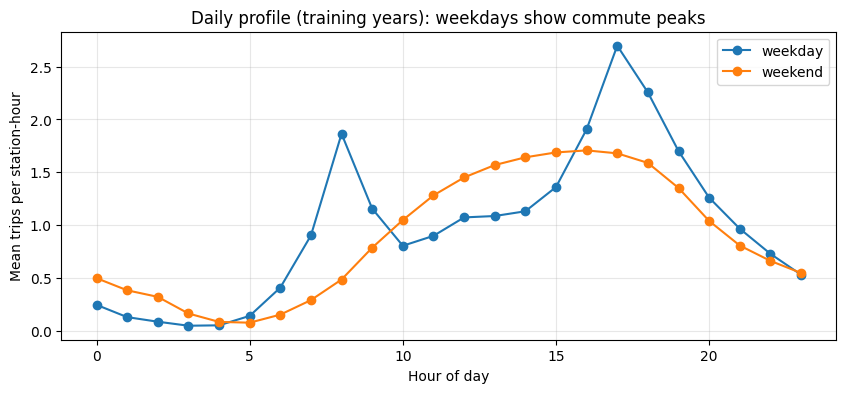

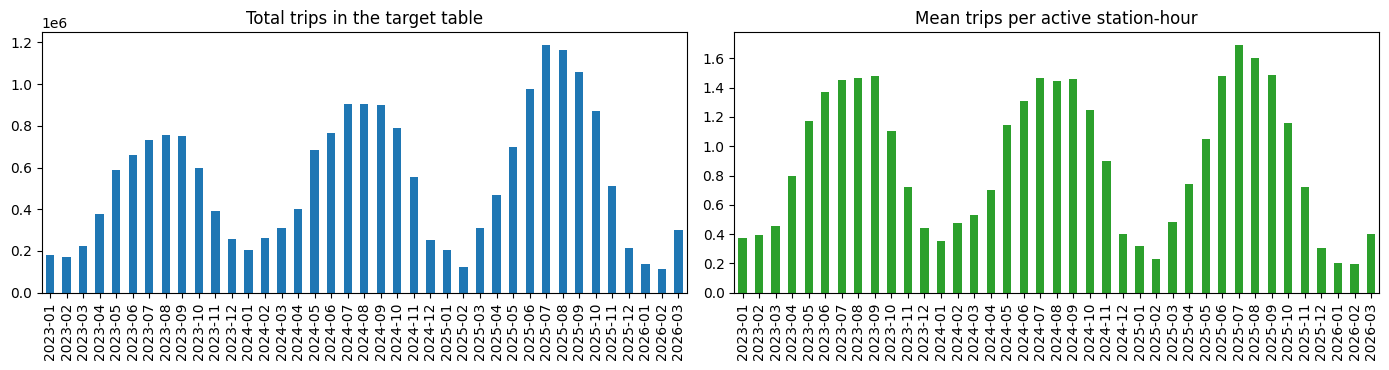

count    903.000
mean       0.876
std        0.924
min        0.000
25%        0.140
50%        0.522
75%        1.359
max        5.475
Name: mean_trips_per_hour, dtype: float64

IQR rule: 25 of 903 stations have a mean above 3.19 trips/hour
Top 10 busiest stations:
             mean_trips_per_hour  zero_share  active_hours
station_id                                               
7006                      5.475       0.206         17542
7076                      5.288       0.253         17542
7033                      4.784       0.213         17542
7030                      4.577       0.217         17542
7542                      4.082       0.232         17542
7016                      4.004       0.356         17542
7078                      3.964       0.249         17542
7418                      3.907       0.205         17542
7038                      3.898       0.294         17542
7720                      3.847       0.214         17542


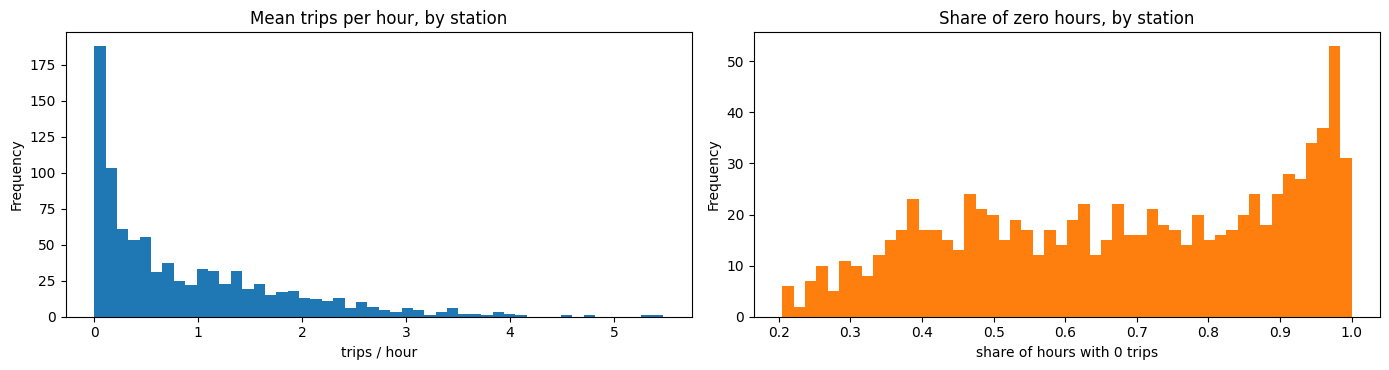

0.9900     10.0
0.9990     19.0
0.9999     33.0
1.0000    174.0
Name: trips, dtype: float64
Station-hours with more than 30 trips: 1851 | more than 50: 290
          station_id                hour  trips
10891813        7171 2024-09-20 23:00:00    174
9807276         7427 2024-07-01 22:00:00    173
10891981        7171 2024-09-27 23:00:00    162
10269805        7171 2024-08-22 23:00:00    157
10269492        7171 2024-08-09 22:00:00    147
10269468        7171 2024-08-08 22:00:00    123
2499804         7171 2023-06-10 23:00:00    112
10269924        7171 2024-08-27 22:00:00    110
10891573        7171 2024-09-10 23:00:00    109
10270501        7172 2024-08-20 23:00:00    106
Autocorrelation of total hourly trips at lag   1 h: 0.896
Autocorrelation of total hourly trips at lag   2 h: 0.726
Autocorrelation of total hourly trips at lag  24 h: 0.899
Autocorrelation of total hourly trips at lag  48 h: 0.825
Autocorrelation of total hourly trips at lag 168 h: 0.909
station_x_hour    42.62
st

In [92]:
# %% ---------------------------------------------------------------------------

# ------------------------------------------------------------------------------

# %% ---------------------------------------------------------------------------


# %% ---------------------------------------------------------------------------



# OBSERVATIONS (complete after running): clear daily double peak on weekdays and a single
# midday hump on weekends; strong seasonality (summer >> winter); demand per station also
# grows over the years, so year/trend and "new station" features matter.

# %% ---------------------------------------------------------------------------


# DECISION: KEEP the busy stations. They are real high-demand locations (downtown,
# waterfront, transit hubs), not errors. Removing them would delete exactly the places
# where predictions matter most. Station identity is therefore an important input.

# %% ---------------------------------------------------------------------------
# 7.5 Extreme station-hours (outliers in the target)
# ------------------------------------------------------------------------------
print(y_train.quantile([0.99, 0.999, 0.9999, 1.0]).rename("trips"))
print("Station-hours with more than 30 trips:", int((y_train > 30).sum()),
      "| more than 50:", int((y_train > 50).sum()))
print(train.nlargest(10, "trips")[["station_id", "hour", "trips"]])

# DECISION: RETAIN the extreme counts (no capping). They come from real peaks (rush hour,
# good weather, events near a station). The trips were already validated in Section 5 (no
# 1-3 s relocks, no multi-day trips), so a high count is a sum of real rides. Capping would
# hide the peaks a demand model needs to learn. If a metric is dominated by a few extreme
# hours later, use a log1p target or a robust metric rather than deleting rows.

# %% ---------------------------------------------------------------------------
# 7.6 Memory of the series: is demand related to past demand?
# ------------------------------------------------------------------------------
system_hourly = hourly[hourly["split"] == "train"].groupby("hour")["trips"].sum().asfreq("h")
for lag in [1, 2, 24, 48, 168]:
    print(f"Autocorrelation of total hourly trips at lag {lag:>3} h: {system_hourly.autocorr(lag):.3f}")

# OBSERVATIONS (complete after running): high autocorrelation at lag 1, 24 and 168 means the
# demand one hour ago, the same hour yesterday and the same hour last week are strong
# inputs (lag features, Section 8).

# %% ---------------------------------------------------------------------------
# 7.7 Which inputs look informative? (share of target variance explained by each variable)
# ------------------------------------------------------------------------------
# One-way "R-squared": how much of the variance of trips is explained if we only know
# the group average of one variable. Higher = more informative on its own. Variables
# are compared on the same scale; interactions are not captured.
def variance_explained(frame, col):
    g = frame.groupby(col)["trips"].agg(["mean", "size"])
    grand = frame["trips"].mean()
    ss_between = (g["size"] * (g["mean"] - grand) ** 2).sum()
    ss_total = ((frame["trips"] - grand) ** 2).sum()
    return ss_between / ss_total

train = train.assign(station_x_hour=train["station_id"].astype("int32") * 24 + train["hour_of_day"])
r2_table = pd.Series({c: variance_explained(train, c)
                      for c in ["station_id", "hour_of_day", "dow", "is_weekend", "month", "year", "station_x_hour"]})
print((r2_table * 100).round(2).sort_values(ascending=False).rename("% of variance explained"))

# OBSERVATIONS (complete after running): station and hour of day (and especially their
# combination) explain the most; weekday/weekend and month add seasonality; year is weak
# on its own because the network also changes. Remaining variance is what weather,
# holidays and recent demand (lags) must explain.

# %% ---------------------------------------------------------------------------
# 7.8 Weather: relationship with hourly demand (OPTIONAL - run after choosing a station)
# ------------------------------------------------------------------------------
# One Toronto weather station is used for all bike stations. Toronto is small compared
# with the spacing of ECCC stations, so nearest-station matching would give nearly the
# same values to most bike stations anyway.
# Set WX_STATION_ID to an ECCC "Station ID" that has HOURLY data for 2023-2026 (check the
# Station Inventory file; also check the missing share of precip_mm below).
# TIME ZONE WARNING: ECCC hourly data is in Local STANDARD Time (UTC-5 all year), but bike
# timestamps are clock time (UTC-4 in summer). to_lst() converts before joining.
WX_STATION_ID = None                      # <- set this, e.g. WX_STATION_ID = 12345
WEATHER_FILE = f"{DATA}/weather/toronto_hourly_weather.csv"
BULK_URL = "https://climate.weather.gc.ca/climate_data/bulk_data_e.html"


def download_hourly_weather(station_id, first_year=2023, last_year=2026, last_month_of_last_year=3):
    frames = []
    for yr in range(first_year, last_year + 1):
        for mo in range(1, 13):
            if yr == last_year and mo > last_month_of_last_year:
                break
            r = requests.get(BULK_URL, params=dict(format="csv", stationID=int(station_id), Year=yr, Month=mo,
                                                   Day=1, timeframe=1, submit="Download+Data"), timeout=60)
            r.raise_for_status()
            frames.append(pd.read_csv(io.StringIO(r.content.decode("utf-8-sig"))))
            time.sleep(0.5)
    w = pd.concat(frames, ignore_index=True)
    precip = w["Precip. Amount (mm)"] if "Precip. Amount (mm)" in w.columns else np.nan
    return pd.DataFrame({"hour_lst": pd.to_datetime(w["Date/Time (LST)"]),
                         "temp_c": w["Temp (°C)"], "precip_mm": precip})


def to_lst(hours):
    """Bike clock hours (America/Toronto) -> Local Standard Time (UTC-5), naive."""
    s = pd.Series(hours)
    local = s.dt.tz_localize("America/Toronto", ambiguous=np.ones(len(s), dtype=bool),
                             nonexistent="shift_forward")
    return local.dt.tz_convert("Etc/GMT+5").dt.tz_localize(None)


if WX_STATION_ID is not None:
    os.makedirs(os.path.dirname(WEATHER_FILE), exist_ok=True)
    if os.path.exists(WEATHER_FILE):
        wx = pd.read_csv(WEATHER_FILE, parse_dates=["hour_lst"])
    else:
        wx = download_hourly_weather(WX_STATION_ID)
        wx.to_csv(WEATHER_FILE, index=False)
    print("Weather rows:", len(wx), "| missing temp %:", round(wx["temp_c"].isna().mean() * 100, 2),
          "| missing precip %:", round(wx["precip_mm"].isna().mean() * 100, 2))

    # one small lookup (one row per clock hour) instead of joining 25M rows on a converted key
    hour_map = pd.DataFrame({"hour": hourly["hour"].drop_duplicates().sort_values().to_numpy()})
    hour_map["hour_lst"] = to_lst(hour_map["hour"])
    wx_by_hour = hour_map.merge(wx, on="hour_lst", how="left").drop(columns="hour_lst")

    sys_mean = (hourly[hourly["split"] == "train"].groupby("hour")["trips"].mean()
                .rename("mean_trips").reset_index().merge(wx_by_hour, on="hour"))
    sys_mean["hod_dow"] = sys_mean["hour"].dt.hour * 7 + sys_mean["hour"].dt.dayofweek
    # remove the typical hour-of-day x weekday pattern so we see the weather effect, not the clock
    sys_mean["demand_resid"] = sys_mean["mean_trips"] - sys_mean.groupby("hod_dow")["mean_trips"].transform("mean")

    print("Spearman correlation with mean trips per station-hour:")
    print(sys_mean[["mean_trips", "demand_resid", "temp_c", "precip_mm"]].corr(method="spearman").round(3)
          .loc[["mean_trips", "demand_resid"], ["temp_c", "precip_mm"]])

    sys_mean["temp_bin"] = pd.cut(sys_mean["temp_c"], [-40, -10, -5, 0, 5, 10, 15, 20, 25, 40])
    print(sys_mean.groupby("temp_bin", observed=True)["mean_trips"].agg(["mean", "size"]).round(3))
    sys_mean["rain_bin"] = pd.cut(sys_mean["precip_mm"], [-0.01, 0, 1, 5, 100], labels=["none", "<=1 mm", "1-5 mm", ">5 mm"])
    print(sys_mean.groupby("rain_bin", observed=True)["mean_trips"].agg(["mean", "size"]).round(3))

    # OBSERVATIONS (complete after running): temperature should be strongly positive
    # (including after removing the clock pattern); rain should lower demand. Missing
    # weather hours need a rule (e.g. interpolate short gaps, or take another station).
else:
    print("WX_STATION_ID not set: weather section skipped.")




### 8. PREPROCESSING AND FEATURE ENGINEERING (final)
 8.1 - Features built from the cleaned hourly table. Each uses information that is known BEFORE the hour being predicted (no leakage).
* calendar : hour_of_day, dow, month, is_weekend, is_holiday (Ontario), sin/cos of hour and month
* history  : demand 1 h, 24 h and 168 h earlier at the same station (lag_1, lag_24, lag_168)
* station  : station_id (categorical), station_age_months, is_new_station (first seen in the last 3 months and after the data start, so growth at a new station is not confused with growing demand)
* weather  : temp_c, precip_mm (joined from 7.8; the station's lat/long can be joined from the Bike Share station_information feed if a spatial feature is wanted)

In [93]:
hourly["hour_sin"] = np.sin(2 * np.pi * hourly["hour_of_day"] / 24).astype("float32")
hourly["hour_cos"] = np.cos(2 * np.pi * hourly["hour_of_day"] / 24).astype("float32")
hourly["month_sin"] = np.sin(2 * np.pi * hourly["month"] / 12).astype("float32")
hourly["month_cos"] = np.cos(2 * np.pi * hourly["month"] / 12).astype("float32")

try:
    import holidays                                                     # pip install holidays
    on_holidays = holidays.Canada(prov="ON", years=range(2023, 2027))
    hourly["is_holiday"] = hourly["hour"].dt.normalize().isin(pd.to_datetime(list(on_holidays.keys())))
except ImportError:
    print("Package 'holidays' not installed (pip install holidays): is_holiday skipped.")

# Lag features. A shifted key is looked up instead of using .shift(), because the table has
# gaps (inactive station-months, removed spring hour) and a row shift would then pick the
# wrong hour. A missing lag becomes NaN (e.g. first week of a station's life).
trips_by_key = hourly.set_index(["station_id", "hour"])["trips"]
for k in [1, 24, 168]:
    key = pd.MultiIndex.from_arrays([hourly["station_id"], hourly["hour"] - pd.Timedelta(hours=k)])
    hourly[f"lag_{k}"] = trips_by_key.reindex(key).to_numpy()
del trips_by_key

first_seen = (station_months.assign(ym=station_months["year"] * 12 + station_months["month"])
              .groupby("Start_Station_Id")["ym"].min())
first_seen_row = hourly["station_id"].map(first_seen)
hourly["station_age_months"] = (hourly["year"] * 12 + hourly["month"] - first_seen_row).astype("float32")
# Stations already present in Jan 2023 are left-censored (true opening date unknown): not "new".
hourly["is_new_station"] = (hourly["station_age_months"] < 3) & (first_seen_row > 2023 * 12 + 1)

# 8.2 Rules for the modelling phase
#   - Split by TIME, never at random: train = 2023-24, test = 2025, final check = 2026 Q1.
#   - Fit scalers / encoders / imputers on the TRAIN rows only, then apply to test.
#   - station_id is an identifier, not a quantity: treat as categorical (one-hot, embedding,
#     or native categorical support in tree models). Stations absent from training (opened in
#     2025-26) are a cold-start case: rely on calendar/weather/neighbour features and report
#     the error for new stations separately.
#   - Rows with a missing lag (first hours of the data / a new station) are dropped for lag
#     models or filled with the station's training mean for tree models.
#   - dst_fallback_hour rows (3 hours in total) can be excluded from training and scoring.
#   - Compare every model to a naive baseline: "same hour last week" (lag_168) and
#     "same hour yesterday" (lag_24).
#   - Primary metrics: MAE and RMSE per station-hour (plus Poisson deviance if a count model).

# 8.3 Save the modelling table and print the closing summary

In [94]:
save_table(hourly, f"{PROCESSED}/hourly_model_table")

removed = int(cleaning_log["drop_short"].sum() + cleaning_log["drop_long"].sum())
print("=" * 70)
print("PREPROCESSING SUMMARY")
print("=" * 70)
print(f"Raw trips                        : {TOTAL_ROWS:,}")
print(f"  removed, shorter than 60 s (R2): {int(cleaning_log['drop_short'].sum()):,}")
print(f"  removed, longer than 6 h  (R3) : {int(cleaning_log['drop_long'].sum()):,}")
print(f"  total removed                  : {removed:,} ({removed / TOTAL_ROWS * 100:.3f}%)")
print(f"Clean trips                      : {int(cleaning_log['clean_rows'].sum()):,}")
print(f"Hourly table (station-hours)     : {len(hourly):,}  x  {hourly.shape[1]} columns")
print(f"Share of zero station-hours      : {(hourly['trips'] == 0).mean() * 100:.1f}%")
print(f"Rows per split                   : {hourly['split'].value_counts().to_dict()}")
print(f"Saved                            : {PROCESSED}/hourly_model_table")

AssertionError: /content/drive/MyDrive/DataSets/processed/hourly_model_table: 23,375,378 rows do not fit in one Excel sheet